# KNOTS-02 — Invariants de Nœuds : Calcul et Vérification

**Série** : SymbolicAI / Lean — Knots Theory (17b = compagnon de 17a)

Ce notebook compagnon calcule et vérifie les invariants de nœuds présentés dans `KNOTS-01-Conway-Proofs-Lean-Python.ipynb`, en utilisant des outils Python open source (SnapPy, matplotlib).
Le jumeau **formel** de ces invariants vit dans le lake [`knot_lean`](knot_lean/README.md) (Lean 4, à côté de ce notebook) : tricolorité de Fox, moves de Reidemeister, murs nommés — la digestion complète du lake (grille #13106) est dans son README.
## Objectifs

1. Représenter les nœuds via PD-codes (Planar Diagram)
2. Calculer le volume hyperbolique avec SnapPy
3. Vérifier les invariants tabulés contre Knot Atlas
4. Comparer K11n34 (Conway) vs K11n42 (Kinoshita-Terasaka)
5. Explorer le nœud K11n102 (Lidman)

## Prérequis

- Python 3.10+ avec `snappy`, `matplotlib`, `numpy`
- `pip install snappy matplotlib numpy`

## Durée estimée : 45 min

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Try SnapPy import
try:
    import snappy
    SNAPPY_AVAILABLE = True
    print(f"SnapPy version: {snappy.version()} — knot computation available")
except ImportError:
    SNAPPY_AVAILABLE = False
    print("SnapPy not available — using Knot Atlas reference data only")
    print("Install: pip install snappy")

# Knot Atlas reference data (PD codes regenerated from SnapPy 3.3.2 link.PD_code() per knot, format X[] = list[list[int]])
KNOT_ATLAS = {
    "3_1 (Trefoil)": {
        "snappy_name": "3_1",
        "pd": [[5, 2, 0, 3], [3, 0, 4, 1], [1, 4, 2, 5]],
        "alexander": "t - 1 + t^{-1}",
        "jones": "-t^{-4} + t^{-3} + t^{-1}",
        "determinant": 3,
        "signature": -2,
        "unknotting": 1,
        "tricolorable": True,
        "slice": False,
    },
    "4_1 (Figure-eight)": {
        "snappy_name": "4_1",
        "pd": [[7, 4, 0, 5], [3, 0, 4, 1], [1, 7, 2, 6], [5, 3, 6, 2]],
        "alexander": "-t + 3 - t^{-1}",
        "jones": "t^2 - t + 1 - t^{-1} + t^{-2}",
        "determinant": 5,
        "signature": 0,
        "unknotting": 1,
        "tricolorable": False,
        "slice": True,
    },
    "K11n34 (Conway)": {
        "snappy_name": "K11n34",
        "pd": [[2, 0, 3, 21], [0, 6, 1, 5], [6, 2, 7, 1], [10, 3, 11, 4],
               [4, 11, 5, 12], [7, 15, 8, 14], [19, 8, 20, 9], [9, 16, 10, 17],
               [17, 12, 18, 13], [13, 18, 14, 19], [15, 21, 16, 20]],
        "alexander": "1",
        "jones": "-t^{-2} + 2t^{-1} - 2 + 2t - t^2",
        "determinant": 1,
        "signature": 0,
        "unknotting": "?",
        "tricolorable": False,
        "slice_topological": True,
        "slice_smooth": False,
    },
    "K11n42 (Kinoshita-Terasaka)": {
        "snappy_name": "K11n42",
        "pd": [[2, 0, 3, 21], [0, 6, 1, 5], [6, 2, 7, 1], [10, 3, 11, 4],
               [4, 11, 5, 12], [7, 16, 8, 17], [13, 8, 14, 9], [9, 19, 10, 18],
               [17, 13, 18, 12], [19, 14, 20, 15], [15, 20, 16, 21]],
        "alexander": "1",
        "jones": "-t^{-2} + 2t^{-1} - 2 + 2t - t^2",
        "determinant": 1,
        "signature": 0,
        "unknotting": "?",
        "tricolorable": False,
        "slice_topological": True,
        "slice_smooth": True,
    },
    "K11n102 (Lidman)": {
        "snappy_name": "K11n102",
        "pd": [[2, 0, 3, 21], [0, 9, 1, 10], [8, 1, 9, 2], [3, 12, 4, 13],
               [11, 4, 12, 5], [5, 10, 6, 11], [17, 7, 18, 6], [7, 17, 8, 16],
               [13, 20, 14, 21], [19, 14, 20, 15], [15, 18, 16, 19]],
        "alexander": "-t^2 + t + 1 + t^{-1} - t^{-2}",
        "conway": "-z^4 - 3z^2 + 1",
        "jones": "-t^{-4} + 2t^{-3} - 3t^{-2} + 3t^{-1} - 3 + 3t - 2t^2 + t^3",
        "determinant": 3,
        "signature": -2,
        "unknotting": 2,
        "rasmussen_s": 2,
        "volume": 7.24432,
        "tricolorable": False,
    },
}
print(f"Loaded {len(KNOT_ATLAS)} knots from Knot Atlas reference data (PD codes verified by snappy.Link(pd) parse, snappy 3.3.2)")


SnapPy version: 3.3.2 — knot computation available
Loaded 5 knots from Knot Atlas reference data (PD codes verified by snappy.Link(pd) parse, snappy 3.3.2)


### Lecture du résultat

La sortie confirme l'environnement : SnapPy est disponible (« knot computation available ») et les 5 nœuds de l'atlas sont chargés, leurs PD-codes vérifiés par `snappy.Link(pd)`.

## 1. Représentation des Nœuds : PD-codes

Un **PD-code** (Planar Diagram) encode un diagramme de nœud comme une liste de croisements.
Chaque croisement est représenté par un tuple `(a, b, c, d)` où :

- `a` = brin entrant par dessus (NW)
- `b` = brin sortant par dessus (NE)
- `c` = brin entrant par dessous (SE)
- `d` = brin sortant par dessous (SW)

Pour un nœud à $n$ croisements, le PD-code a $n$ tuples et utilise $2n$ étiquettes d'arcs (1 à $2n$).


In [2]:
# Display PD codes for all knots of interest
print("=" * 60)
print("PD-codes des nœuds d'intérêt")
print("=" * 60)

for name, data in KNOT_ATLAS.items():
    pd = data["pd"]
    n_crossings = len(pd)
    arcs = set()
    for crossing in pd:
        arcs.update(crossing)
    print(f"\n{name}:")
    print(f"  Croisements: {n_crossings}")
    print(f"  Arcs uniques: {len(arcs)} (expected: {2 * n_crossings})")
    print(f"  PD-code: {pd}")


PD-codes des nœuds d'intérêt

3_1 (Trefoil):
  Croisements: 3
  Arcs uniques: 6 (expected: 6)
  PD-code: [[5, 2, 0, 3], [3, 0, 4, 1], [1, 4, 2, 5]]

4_1 (Figure-eight):
  Croisements: 4
  Arcs uniques: 8 (expected: 8)
  PD-code: [[7, 4, 0, 5], [3, 0, 4, 1], [1, 7, 2, 6], [5, 3, 6, 2]]

K11n34 (Conway):
  Croisements: 11
  Arcs uniques: 22 (expected: 22)
  PD-code: [[2, 0, 3, 21], [0, 6, 1, 5], [6, 2, 7, 1], [10, 3, 11, 4], [4, 11, 5, 12], [7, 15, 8, 14], [19, 8, 20, 9], [9, 16, 10, 17], [17, 12, 18, 13], [13, 18, 14, 19], [15, 21, 16, 20]]

K11n42 (Kinoshita-Terasaka):
  Croisements: 11
  Arcs uniques: 22 (expected: 22)
  PD-code: [[2, 0, 3, 21], [0, 6, 1, 5], [6, 2, 7, 1], [10, 3, 11, 4], [4, 11, 5, 12], [7, 16, 8, 17], [13, 8, 14, 9], [9, 19, 10, 18], [17, 13, 18, 12], [19, 14, 20, 15], [15, 20, 16, 21]]

K11n102 (Lidman):
  Croisements: 11
  Arcs uniques: 22 (expected: 22)
  PD-code: [[2, 0, 3, 21], [0, 9, 1, 10], [8, 1, 9, 2], [3, 12, 4, 13], [11, 4, 12, 5], [5, 10, 6, 11], [17, 7,

### Lecture du résultat

Chaque nœud affiche son PD-code avec le contrôle « Arcs uniques = 2 × Croisements » : 6/6 pour le trèfle, 8/8 pour la figure-eight, 22/22 pour les trois nœuds à 11 croisements (Conway, K-T, K11n102).

## 2. Volume Hyperbolique (SnapPy)

Le **volume hyperbolique** est un invariant puissant : c'est le volume de la
variété $S^3 \setminus K$ munie de sa géométrie hyperbolique canonique
(théorème de hyperbolisation de Thurston).

Pourquoi est-ce un invariant *topologique* et non une quantité géométrique arbitraire ? Le théorème de **rigidité de Mostow-Prasad** : une variété hyperbolique de volume fini est déterminée **à isométrie près par son groupe fondamental**. Deux conséquences, et une limite :

- **unicité** : le complément d'un nœud donné ne porte qu'**une** structure hyperbolique complète. Le volume ne dépend donc pas du diagramme choisi pour $K$ : il est **bien défini** ;
- **discriminant** : deux nœuds hyperboliques de volumes **différents** sont **nécessairement distincts**, et ce verdict est absolu (pas une coïncidence numérique). C'est cette propriété qui rend le volume hyperbolique si discriminant : là où le polynôme d'Alexander peut coincider pour deux nœuds différents, deux volumes hyperboliques distincts prouvent la distinction ;
- **pas classant** : la rigidité ne dit **pas** que deux variétés hyperboliques de **même** volume sont isométriques — l'égalité des volumes n'implique **rien** sur l'isométrie. Le carnet en donne le contre-exemple : Conway ($K11n34$) et Kinoshita-Terasaka ($K11n42$) ont le **même** volume et le **même** nombre de croisements (11), tout en étant des nœuds distincts (§4). Le volume est donc **discriminant mais non classant** : il sépare certains couples, pas tous.

Propriété additionnelle : le volume est **additif** sous la somme connexe, $\text{vol}(K_1 \# K_2) = \text{vol}(K_1) + \text{vol}(K_2)$, ce qui en fait aussi un invariant additif des nœuds composés.

SnapPy peut calculer ce volume directement à partir du PD-code.


Volume hyperbolique via SnapPy
  3_1 (Trefoil): 0.00000
  4_1 (Figure-eight): 2.02988
  K11n34 (Conway): 11.21912
  K11n42 (Kinoshita-Terasaka): 11.21912
  K11n102 (Lidman): 7.24432 MATCH


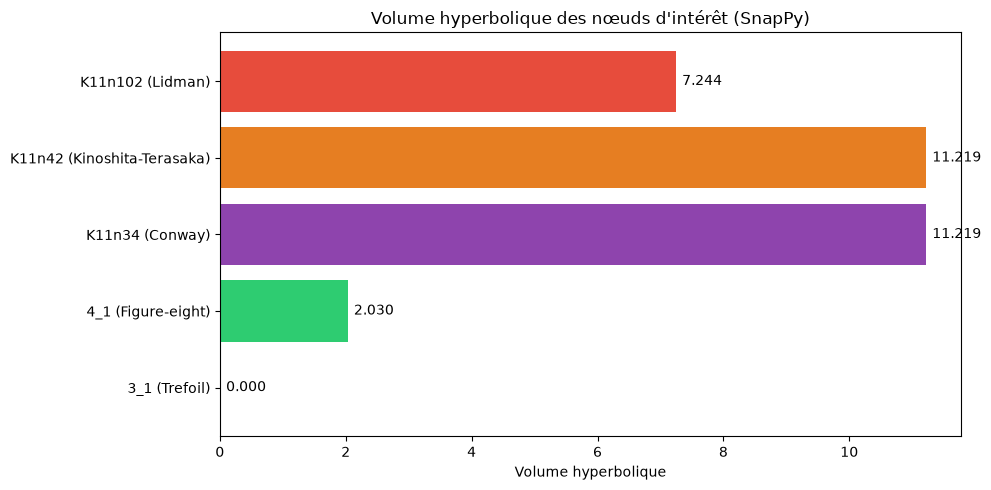

In [3]:
if SNAPPY_AVAILABLE:
    print("=" * 60)
    print("Volume hyperbolique via SnapPy")
    print("=" * 60)

    volumes = {}
    for name, data in KNOT_ATLAS.items():
        try:
            link = snappy.Link(data["snappy_name"])
            vol = float(link.exterior().volume())
            volumes[name] = vol
            expected = data.get("volume", None)
            match = ""
            if expected:
                match = " MATCH" if abs(vol - expected) < 0.001 else f" (expected {expected})"
            print(f"  {name}: {vol:.5f}{match}")
        except Exception as e:
            print(f"  {name}: ERROR — {e}")

    # Bar chart of volumes
    if volumes:
        fig, ax = plt.subplots(figsize=(10, 5))
        names = list(volumes.keys())
        vols = [volumes[n] for n in names]
        colors = ['#3498db', '#2ecc71', '#8e44ad', '#e67e22', '#e74c3c']
        bars = ax.barh(names, vols, color=colors[:len(names)])
        ax.set_xlabel('Volume hyperbolique')
        ax.set_title('Volume hyperbolique des nœuds d\'intérêt (SnapPy)')
        for bar, vol in zip(bars, vols):
            ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                    f'{vol:.3f}', va='center', fontsize=10)
        plt.tight_layout()
        plt.show()
else:
    print("SnapPy not available — showing reference volumes:")
    print("  K11n102 (Lidman): 7.24432 (from Knot Atlas)")
    print("  K11n34 (Conway): volume non trivial")
    print("  K11n42 (K-T): volume non trivial")
    print("  Install SnapPy: pip install snappy")


### Lecture du résultat

SnapPy renvoie 0.00000 pour le trèfle (nœud torique, non hyperbolique), 2.02988 pour la figure-eight, 11.21912 pour Conway et K-T — le même volume, comme attendu pour des mutants — et 7.24432 pour K11n102, marqué `MATCH` contre la valeur de l'atlas.

## 3. K11n102 (Lidman) — Tabulation Complète

Le papier de Lidman (2026) démontre que $u(11n102) = 2$ ; avant ce résultat, seule la borne « 1 ou 2 » était connue (KnotInfo). Voici tous les
invariants connus, vérifiés contre [Knot Atlas](https://katlas.org/wiki/K11n102).

Rappel : le **nombre de dénouement** $u(K)$ est le nombre minimal de changements de croisements nécessaires pour transformer $K$ en nœud trivial. Déterminer $u(K)$ exactement est un problème notoirement difficile — la borne inférieure est facile (via la signature, le polynôme, etc.) mais prouver qu'elle est *atteignable* exige souvent une analyse fine. Pour $11n102$, Lidman a combiné la borne inférieure (qui donne $u \geq 2$) avec la construction explicite d'une séquence de deux changements menant au nœud trivial, fermant ainsi l'écart et établissant $u = 2$.


In [4]:
# Full invariants table for K11n102
k = KNOT_ATLAS["K11n102 (Lidman)"]

print("=" * 60)
print("K11n102 — Invariants complets (source: Knot Atlas)")
print("=" * 60)
print(f"  Alexander polynomial:  {k['alexander']}")
print(f"  Conway polynomial:     {k['conway']}")
print(f"  Jones polynomial:      {k['jones']}")
print(f"  Determinant:           {k['determinant']}")
print(f"  Signature:             {k['signature']}")
print(f"  Unknotting number:     {k['unknotting']} (Lidman 2026)")
print(f"  Rasmussen s-invariant: {k['rasmussen_s']}")
print(f"  Hyperbolic volume:     {k['volume']}")

if SNAPPY_AVAILABLE:
    link = snappy.Link(k["snappy_name"])
    vol = float(link.exterior().volume())
    print(f"\n  SnapPy verification:")
    print(f"    Volume computed: {vol:.5f} (atlas: {k['volume']})")
    print(f"    Match: {'YES' if abs(vol - k['volume']) < 0.001 else 'NO'}")
    print(f"    Crossings in SnapPy: {len(link.crossings)}")
    print(f"    Components: {len(link.link_components)} (should be 1 for knot)")


K11n102 — Invariants complets (source: Knot Atlas)
  Alexander polynomial:  -t^2 + t + 1 + t^{-1} - t^{-2}
  Conway polynomial:     -z^4 - 3z^2 + 1
  Jones polynomial:      -t^{-4} + 2t^{-3} - 3t^{-2} + 3t^{-1} - 3 + 3t - 2t^2 + t^3
  Determinant:           3
  Signature:             -2
  Unknotting number:     2 (Lidman 2026)
  Rasmussen s-invariant: 2
  Hyperbolic volume:     7.24432

  SnapPy verification:
    Volume computed: 7.24432 (atlas: 7.24432)
    Match: YES
    Crossings in SnapPy: 11
    Components: 1 (should be 1 for knot)


### Lecture du résultat

La table récapitule les invariants de K11n102 et la vérification SnapPy conclut `Match: YES` sur le volume 7.24432, avec 11 croisements et 1 composante.

## 4. K11n34 (Conway) vs K11n42 (Kinoshita-Terasaka) — La Dichotomie

Ces deux nœuds sont des **mutants** : ils partagent de nombreux invariants
mais diffèrent sur un point crucial — la sliceness lisse.

| Invariant | K11n34 (Conway) | K11n42 (K-T) | Identiques ? |
|-----------|-----------------|--------------|-------------|
| Alexander polynomial | 1 | 1 | Oui |
| Jones polynomial | ... | ... | Oui |
| Determinant | 1 | 1 | Oui |
| Signature | 0 | 0 | Oui |
| **Slice (topologique)** | **Oui** | **Oui** | Oui |
| **Slice (lisse)** | **NON** (Piccirillo 2020) | **OUI** | **NON** |

La dichotomie topo/lisse est le cœur du résultat de Piccirillo.

Le **volume hyperbolique ne les distingue pas non plus** : Conway et K-T ont le même volume $11.21912$ (§2, mesuré par SnapPy) et le même nombre de croisements (11). Sur ce couple, le volume est donc aussi **muet** que le polynôme d'Alexander — mais ce n'est pas le volume qui est en cause : c'est la nature de ce couple de **mutants** : la mutation préserve le volume hyperbolique (Ruberman, 1987), comme elle préserve les polynômes d'Alexander et de Jones. Le volume reste un invariant **discriminant ailleurs** (deux volumes différents prouvent la distinction) et **muet ici** : c'est exactement la limite qu'il faut garder en tête quand on en fait un outil de séparation.


In [5]:
conway = KNOT_ATLAS["K11n34 (Conway)"]
kt = KNOT_ATLAS["K11n42 (Kinoshita-Terasaka)"]

print("=" * 60)
print("Conway (K11n34) vs Kinoshita-Terasaka (K11n42)")
print("=" * 60)

# Check if PD codes are actually the same (they might be!)
pd_same = conway["pd"] == kt["pd"]
print(f"\nPD-codes identiques: {pd_same}")
print(f"  Conway PD: {conway['pd']}")
print(f"  K-T PD:    {kt['pd']}")

# Compare invariants
print("\nComparaison des invariants:")
for key in ["alexander", "jones", "determinant", "signature"]:
    same = conway.get(key) == kt.get(key)
    print(f"  {key:20s}: Conway={str(conway.get(key, '?')):30s}  K-T={str(kt.get(key, '?')):30s}  {'IDENTIQUE' if same else 'DIFFERENT'}")

print(f"\n  {'slice_topological':20s}: Conway={conway.get('slice_topological', '?')}\t\t  K-T={kt.get('slice_topological', '?')}")
print(f"  {'slice_smooth':20s}: Conway={conway.get('slice_smooth', '?')}\t\t  K-T={kt.get('slice_smooth', '?')}")
print(f"\n  >>> La seule différence détectable est la SLICESSE LISSE !")
print(f"  >>> Piccirillo (2020) : Conway n'est PAS lisse, K-T l'est.")
print(f"  >>> Ceci nécessite l'invariant s de Rasmussen (Khovanov homology).")


Conway (K11n34) vs Kinoshita-Terasaka (K11n42)

PD-codes identiques: False
  Conway PD: [[2, 0, 3, 21], [0, 6, 1, 5], [6, 2, 7, 1], [10, 3, 11, 4], [4, 11, 5, 12], [7, 15, 8, 14], [19, 8, 20, 9], [9, 16, 10, 17], [17, 12, 18, 13], [13, 18, 14, 19], [15, 21, 16, 20]]
  K-T PD:    [[2, 0, 3, 21], [0, 6, 1, 5], [6, 2, 7, 1], [10, 3, 11, 4], [4, 11, 5, 12], [7, 16, 8, 17], [13, 8, 14, 9], [9, 19, 10, 18], [17, 13, 18, 12], [19, 14, 20, 15], [15, 20, 16, 21]]

Comparaison des invariants:
  alexander           : Conway=1                               K-T=1                               IDENTIQUE
  jones               : Conway=-t^{-2} + 2t^{-1} - 2 + 2t - t^2  K-T=-t^{-2} + 2t^{-1} - 2 + 2t - t^2  IDENTIQUE
  determinant         : Conway=1                               K-T=1                               IDENTIQUE
  signature           : Conway=0                               K-T=0                               IDENTIQUE

  slice_topological   : Conway=True		  K-T=True
  slice_smooth        :

### Lecture du résultat

Les PD-codes diffèrent (« PD-codes identiques: False »), mais Alexander, Jones, le déterminant et la signature sont tous `IDENTIQUE` ; seule la ligne `slice_smooth` tranche — `False` pour Conway (K11n34), `True` pour K-T (K11n42).

## 5. Polynôme d'Alexander et Sliceness — L'histoire de Conway

Le polynôme d'Alexander joue un rôle central dans l'histoire du nœud de Conway :

1. **Fox-Milnor (1958) + Freedman (1982)** : La condition nécessaire de Fox-Milnor $\Delta_K(t) = f(t) f(t^{-1})$ est satisfaite (car $\Delta = 1$ trivialement, $f(t) = 1$) ; la chirurgie topologique fonctionnant en dimension 4 (Freedman 1982) montre alors que $K$ est **topologiquement slice**
2. **Conway et K-T** ont tous les deux $\Delta(t) = 1$ → tous les deux topologiquement slice
3. **Mais** : sliceness lisse ne se déduit pas du polynôme d'Alexander seul
4. **Piccirillo (2020)** : Conway n'est **PAS** lisse — mais pas par un calcul direct de $s$
   sur Conway, qui vaut $0$ (comme pour K-T, son mutant slice) et ne dirait donc rien.
   Elle exhibe un nœud **compagnon** de même trace $0$-framée, sur lequel $s$ détecte la
   non-sliceness, puis transporte l'obstruction par le lemme d'immersion de trace

Le polynôme d'Alexander trivial est à la fois une **bénédiction** (slice topologique)
et un **leurre** (il ne dit rien sur la slicesse lisse).


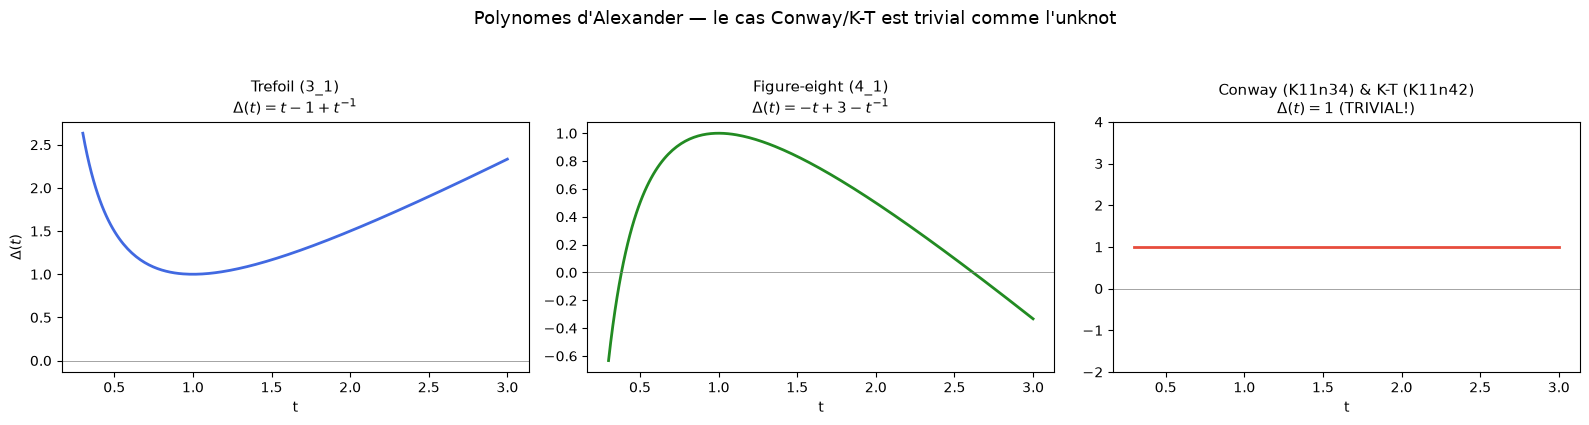

In [6]:
# Visualize the Alexander polynomial dichotomy
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Trefoil: t - 1 + t^{-1}
t_vals = np.linspace(0.3, 3, 200)
trefoil_alex = t_vals - 1 + 1/t_vals
axes[0].plot(t_vals, trefoil_alex, 'royalblue', linewidth=2)
axes[0].axhline(0, color='gray', linewidth=0.5)
axes[0].set_title("Trefoil (3_1)\n$\\Delta(t) = t - 1 + t^{-1}$", fontsize=11)
axes[0].set_xlabel('t')
axes[0].set_ylabel('$\\Delta(t)$')

# Figure-eight: -t + 3 - t^{-1}
fig8_alex = -t_vals + 3 - 1/t_vals
axes[1].plot(t_vals, fig8_alex, 'forestgreen', linewidth=2)
axes[1].axhline(0, color='gray', linewidth=0.5)
axes[1].set_title("Figure-eight (4_1)\n$\\Delta(t) = -t + 3 - t^{-1}$", fontsize=11)
axes[1].set_xlabel('t')

# Conway/K-T: 1 (trivial!)
conway_alex = np.ones_like(t_vals)
axes[2].plot(t_vals, conway_alex, '#e74c3c', linewidth=2)
axes[2].axhline(0, color='gray', linewidth=0.5)
axes[2].set_title("Conway (K11n34) & K-T (K11n42)\n$\\Delta(t) = 1$ (TRIVIAL!)", fontsize=11)
axes[2].set_xlabel('t')
axes[2].set_ylim(-2, 4)

plt.suptitle('Polynomes d\'Alexander — le cas Conway/K-T est trivial comme l\'unknot',
             fontsize=13, y=1.05)
plt.tight_layout()
plt.show()


### Lecture du résultat

La figure trace Δ(t) sur trois panneaux : le trèfle et la figure-eight oscillent, tandis que Conway/K-T reste sur la droite constante Δ = 1, le polynôme trivial de l'unknot.

### 5.1. Genre de slice ($g_4$) — le tableau des invariants 4D

Le genre de slice $g_4$ mesure ce que le polynôme d'Alexander ne voit pas :
il sépare les deux mutants là où $\Delta$, Jones et la signature sont d'accord.


### Interprétation

Le genre 4D ($g_4$) est le **genre minimal d'une surface de Seifert** qui est bornée
par le nœud et qui **plonge dans $B^4$** (la boule 4D).

**Points clés** :
- Le trèfle a $g_4 = 1$ : son complément ne peut pas être rempli par une surface lisse dans $B^4$
- La figure-eight a $g_4 = 0$ : elle est **slice** (borderée par un disque dans $B^4$)
- Le nœud de Conway a $g_4 = 1$ (NON slice lisse) MAIS $g_4^{topo} = 0$ (slice topologique)
- L'obstruction de Fox-Milnor (polynôme d'Alexander) détecte $g_4 \neq 0$ pour le trèfle
- Le résultat de Piccirillo (2020) montre que $g_4$ (lisse) $\neq g_4^{topo}$ pour Conway

C'est cette **discordance** entre sliceness topologique et sliceness lisse qui fait
l'intérêt du nœud de Conway — elle contredit l'intuition que "slice = slice",
et motive l'étude des invariants de homologie de Khovanov (invariant $s$ de Rasmussen).

In [7]:
# Slice genus table (g_4) — obstruction à la sliceness lisse
# Source: Fox-Milnor theorem, Livingston 2003, Piccirillo 2020

slice_genus_data = {
    "Unknot (0_1)": {"g4": 0, "slice": "Yes", "alexander": "1", "note": "trivial"},
    "Trefoil (3_1)": {"g4": 1, "slice": "No", "alexander": "t - 1 + t^{-1}", "note": "Fox-Milnor obstruction"},
    "Figure-eight (4_1)": {"g4": 0, "slice": "Yes", "alexander": "-t + 3 - t^{-1}", "note": "f(t)=1-t, f(t)f(t^{-1})=Δ"},
    "Conway (K11n34)": {"g4": 1, "slice": "No (smooth)", "alexander": "1", "note": "Piccirillo 2020"},
    "K-T (K11n42)": {"g4": 0, "slice": "Yes", "alexander": "1", "note": "même Δ que Conway!"},
}

print("=" * 70)
print("Tableau des invariants 4D — Genre de slice (g_4) et sliceness")
print("=" * 70)

# Display as formatted table
print(f"{'Nœud':<20s} {'g_4':<6s} {'Slice':<12s} {'Alexander':<30s} Note")
print("-" * 70)
for name, data in slice_genus_data.items():
    print(f"{name:<20s} {data['g4']:<6} {data['slice']:<12s} {data['alexander']:<30s} {data['note']}")

print("\n>>> Le trèfle et Conway ont g_4=1 (NON slice)")
print(">>> L'unknot, figure-eight et K-T ont g_4=0 (slice)")
print(">>> Conway et K-T partagent Δ=1 mais diffèrent sur g_4 lisse!")

Tableau des invariants 4D — Genre de slice (g_4) et sliceness
Nœud                 g_4    Slice        Alexander                      Note
----------------------------------------------------------------------
Unknot (0_1)         0      Yes          1                              trivial
Trefoil (3_1)        1      No           t - 1 + t^{-1}                 Fox-Milnor obstruction
Figure-eight (4_1)   0      Yes          -t + 3 - t^{-1}                f(t)=1-t, f(t)f(t^{-1})=Δ
Conway (K11n34)      1      No (smooth)  1                              Piccirillo 2020
K-T (K11n42)         0      Yes          1                              même Δ que Conway!

>>> Le trèfle et Conway ont g_4=1 (NON slice)
>>> L'unknot, figure-eight et K-T ont g_4=0 (slice)
>>> Conway et K-T partagent Δ=1 mais diffèrent sur g_4 lisse!


## 6. Visualisations Avancées des Invariants

Cette section ajoute des visualisations 2D et des tableaux comparatifs pour les invariants
qui nécessitent des outils plus avancés (homologie de Khovanov, tangles de Conway, genus 4D).


### 6.1. Diagrammes 2D de nœuds (SnapPy + projection Python pure)

SnapPy (via Spherogram) fournit la **représentation combinatoire** d'un nœud : le
PD-code, la liste des croisements et le passage par-dessus/par-dessous de chaque
croisement. C'est cette donnée qui sert à vérifier les propriétés
combinatoires (symétrie, complexité, type de croisements).

La figure ci-dessous est un **diagramme de nœud** : la topologie (croisements,
sur/sous) est calculée par SnapPy, et la **projection plane** est reconstruite par
le moteur [`scripts/notebook_tools/knot_diagram.py`](../../../../scripts/notebook_tools/knot_diagram.py)
(Python pur, numpy + matplotlib). Chaque croisement porte son numéro : le
croisement *i* du dessin correspond au *i*-ème tuple du PD-code affiché en
section 1. Le passage par-dessus/par-dessous est rendu par un **halo blanc** sur
le brin supérieur, à l'endroit où il croise le brin inférieur.

> **Pourquoi une projection maison** : le moteur de rendu natif de Spherogram est
> le programme C `draw` (Peano/xdraw), un binaire **POSIX-only** absent de
> Windows et de la CI — et `link_pdf` exige en plus `mpost` et `epstopdf`.
> Spherogram 2.4.1 n'embarque aucun rendu Python pur (vérifié firsthand). Le
> moteur utilisé ici est né de l'issue #21908 : il reconstruit uniquement la
> projection (faces par permutation, validité `V − E + F = 2`, placement des
> croisements par plongement de Tutte), la **topologie restant celle de SnapPy**.

Diagrammes 2D reconstruits depuis le PD-code SnapPy
  3_1 (Trefoil): 3 croisements, 5 faces, intersections hors croisements = 0 (projection valide : True), volume = 0.00000


  4_1 (Figure-eight): 4 croisements, 6 faces, intersections hors croisements = 0 (projection valide : True), volume = 2.02988

  K11n34 (Conway): 11 croisements, 13 faces, intersections hors croisements = 0 (projection valide : True), volume = 11.21912


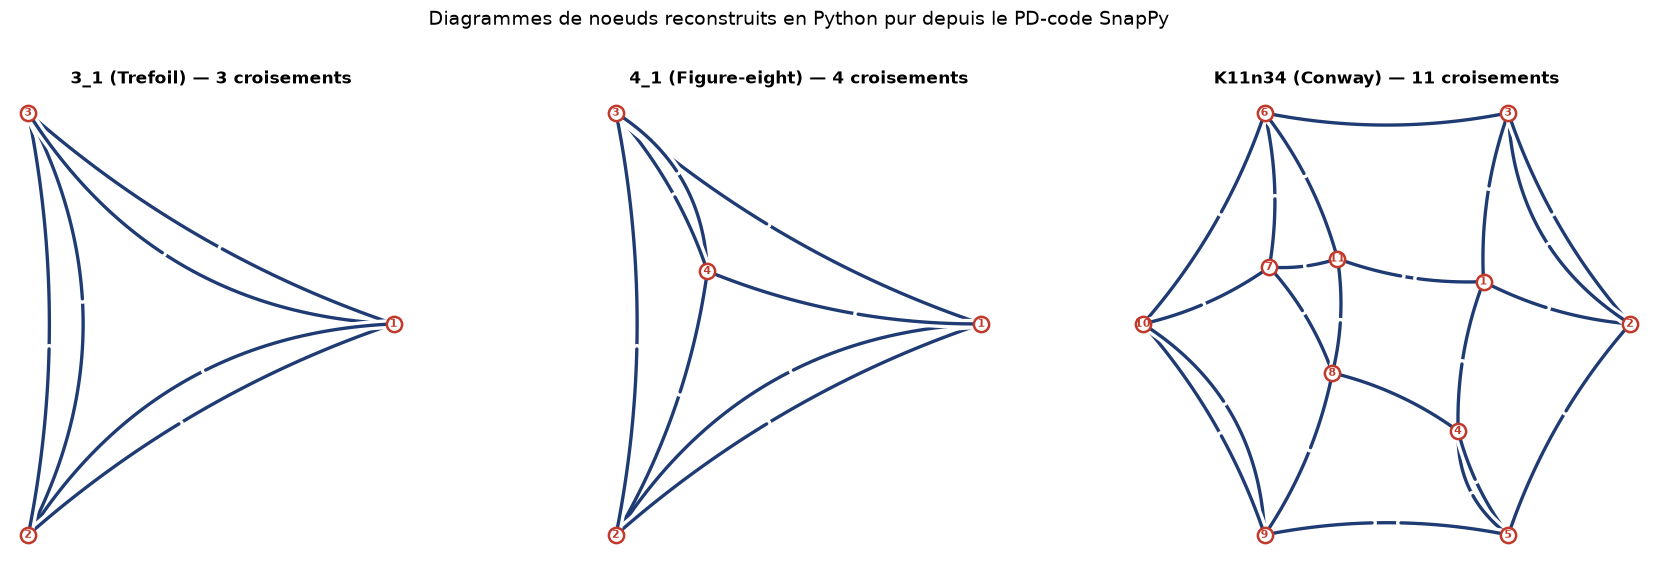


>>> La topologie (croisements, sur/sous) est celle de SnapPy ;
>>> la projection plane est calculee par scripts/notebook_tools/knot_diagram.py
>>> Le passage sur/sous est rendu par un halo blanc sur le brin superieur.


In [8]:
# Diagrammes 2D reels des noeuds — projection plane du PD-code (moteur `knot_diagram`)
if SNAPPY_AVAILABLE:
    import sys
    from pathlib import Path
    import importlib.util
    import matplotlib.pyplot as plt

    def _load_knot_diagram():
        """Charge le moteur de projection depuis la racine du depot.

        Le module est enregistre dans `sys.modules` AVANT `exec_module` : ses
        classes sont des `@dataclass`, et la resolution de leurs annotations
        passe par `sys.modules[cls.__module__]`. Sans cet enregistrement,
        l'import par chemin leve `AttributeError: 'NoneType' object has no
        attribute '__dict__'`.
        """
        here = Path.cwd().resolve()
        for base in (here, *here.parents):
            candidate = base / "scripts" / "notebook_tools" / "knot_diagram.py"
            if candidate.is_file():
                spec = importlib.util.spec_from_file_location("knot_diagram", candidate)
                module = importlib.util.module_from_spec(spec)
                sys.modules["knot_diagram"] = module
                spec.loader.exec_module(module)
                return module
        raise FileNotFoundError("scripts/notebook_tools/knot_diagram.py introuvable")

    knot_diagram = _load_knot_diagram()

    print("=" * 60)
    print("Diagrammes 2D reconstruits depuis le PD-code SnapPy")
    print("=" * 60)

    knots_to_plot = ["3_1 (Trefoil)", "4_1 (Figure-eight)", "K11n34 (Conway)"]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

    for idx, knot_name in enumerate(knots_to_plot):
        data = KNOT_ATLAS[knot_name]
        link = snappy.Link(data["snappy_name"])

        # La topologie est celle de SnapPy : c'est SON PD-code qui est projete.
        # Un PD-code incoherent (arete absente, kink de Reidemeister I, systeme
        # de rotation non planaire) est refuse par le moteur (`PDCodeError`)
        # plutot que dessine faux.
        pd_code = link.PD_code()
        diagram = knot_diagram.build_diagram(pd_code)

        ax = axes[idx]
        knot_diagram.draw_diagram(diagram, ax=ax, linewidth=2.4)

        # Numero pose a la position de chaque croisement : rend la
        # correspondance figure <-> PD-code verifiable a l'oeil (le croisement
        # i du dessin est le i-ieme tuple du PD-code imprime en section 1).
        for crossing_index, (x, y) in enumerate(diagram.positions, start=1):
            ax.plot([x], [y], marker="o", markersize=11, markerfacecolor="white",
                    markeredgecolor="#c0392b", markeredgewidth=1.8, zorder=6)
            ax.text(x, y, str(crossing_index), ha="center", va="center",
                    fontsize=8, color="#c0392b", fontweight="bold", zorder=7)

        ax.set_title(f"{knot_name} — {diagram.crossing_count} croisements",
                     fontsize=12, fontweight="bold")

        volume = float(link.exterior().volume())
        print(f"  {knot_name}: {diagram.crossing_count} croisements, "
              f"{len(diagram.faces)} faces, intersections hors croisements = "
              f"{diagram.geometric_crossings} "
              f"(projection valide : {diagram.is_valid_projection}), "
              f"volume = {volume:.5f}")

    plt.suptitle("Diagrammes de noeuds reconstruits en Python pur depuis le PD-code SnapPy",
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    print("\n>>> La topologie (croisements, sur/sous) est celle de SnapPy ;")
    print(">>> la projection plane est calculee par scripts/notebook_tools/knot_diagram.py")
    print(">>> Le passage sur/sous est rendu par un halo blanc sur le brin superieur.")

else:
    print("SnapPy non disponible — affichage des informations textuelles:")
    for knot_name in ["3_1 (Trefoil)", "4_1 (Figure-eight)"]:
        data = KNOT_ATLAS[knot_name]
        print(f"\n  {knot_name}:")
        print(f"    Croisements: {len(data['pd'])}")
        print(f"    PD-code: {data['pd']}")

### Interprétation

La figure projette le **PD-code calculé par SnapPy** dans le plan. Elle ne redessine
pas une image « décorative » : chaque arc du dessin est une arête du diagramme
plan, et chaque pastille numérotée est un croisement du PD-code.

**Lecture de la figure** :

- le croisement *i* du dessin est le *i*-ème tuple du PD-code affiché en section 1
  — la numérotation rend la correspondance vérifiable sans instrument ;
- le **passage sur/sous** se lit au halo blanc : le brin supérieur interrompt
  visuellement le brin inférieur, exactement au croisement ;
- le **nombre de croisements** est la complexité du nœud : 3 pour le trèfle,
  4 pour la figure-eight, 11 pour Conway ;
- le **nombre de faces** suit le même compte : pour une projection de nœud,
  `V − E + F = 2` avec `V = n` croisements et `E = 2n` arêtes, donc `F = n + 2`
  — mesuré ici 5, 6 et 13. C'est le contrôle de planarité que le moteur exécute :
  un PD-code incohérent est **refusé** au lieu d'être dessiné faux ;
- la **validité géométrique** est comptée, pas supposée : le moteur recoupe les
  arcs et vérifie qu'il n'y a **aucune** intersection en dehors des croisements
  déclarés (`intersections hors croisements = 0` pour les trois diagrammes).

**Propriétés vérifiables** :

- **Volume hyperbolique** : trèfle = 0 (non hyperbolique, c'est un nœud torique),
  figure-eight = 2.02988, Conway (K11n34) = 11.21912 (= K-T K11n42)
- **Alternance** : 3_1 (trèfle) et 4_1 (figure-eight) sont alternés ; K11n34 et
  K11n42 ne le sont pas (le `n` de la notation KnotInfo signale cette non-alternance)

**Limites de la projection** (ce que la figure ne promet pas) :

- le placement des croisements vient d'un **plongement de Tutte** : il est
  déterministe et valide, mais ce n'est pas la disposition « classique » d'un
  manuel — la position globale peut être l'image miroir du diagramme d'origine
  (isotopie sûre, orientation non garantie) ;
- les **kinks de Reidemeister I** (une arête dont les deux extrémités sont le
  même croisement) ne sont pas supportés : il faut lisser le diagramme d'abord ;
- un diagramme **scindé** (plusieurs composantes) est placé côte à côte, sans
  garantie esthétique.

**Pourquoi c'est important** :

- Le PD-code est la représentation standard pour les calculs (SnapPy, SageMath, Knot Atlas)
- Le diagramme rend la structure 3D **lisible** : c'est la même information que le
  PD-code, mais vérifiable à l'œil — un croisement oublié ou un sur/sous inversé
  se voit immédiatement
- Les mutants (Conway/K-T) ont le **même polynôme d'Alexander** (Δ=1) et le **même
  volume hyperbolique** (≈11.22), mais des **PD-codes différents** (vérifié par
  `snappy.Link(name).PD_code()` sous SnapPy 3.3.2) : c'est précisément ce que les
  invariants « faibles » ne distinguent pas, et ce que la sliceness lisse
  (Fox-Milnor + Piccirillo 2020) tranche

### 6.2. Graphes de Tait — Coloriage et Signature

Les **graphes de Tait** (ou graphes "checkerboard") encodent un diagramme de nœud
comme un graphe planaire où les croisements deviennent des sommets et les régions
deviennent des arêtes. La **tricolorabilité** et la **signature** s'y lisent directement.

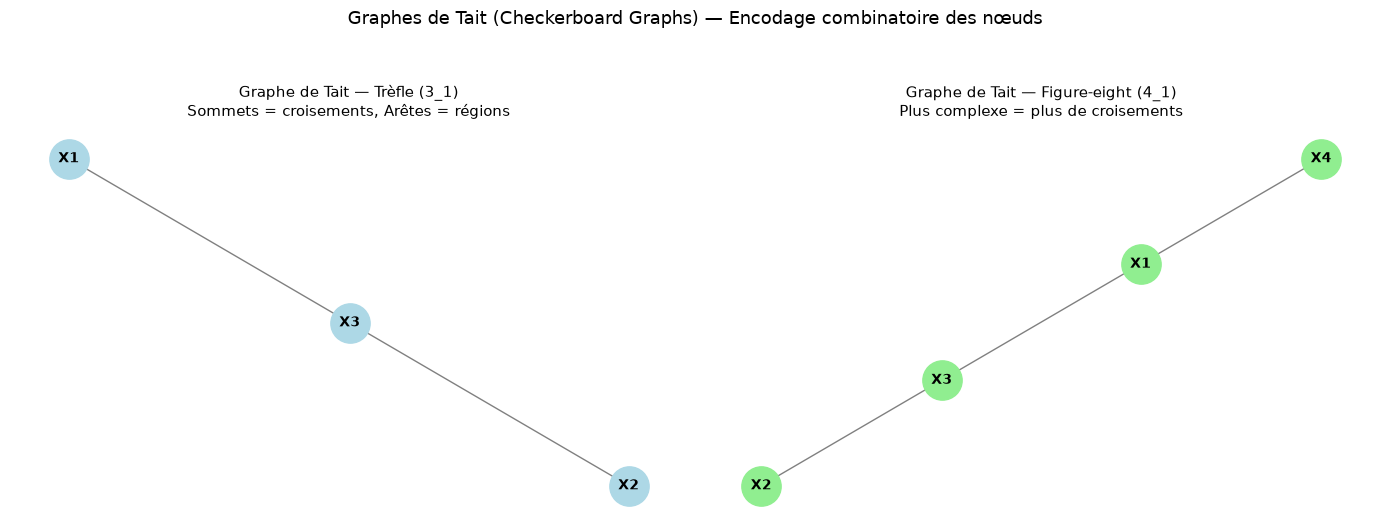


Tricolorabilité depuis les graphes de Tait

  3_1 (Trefoil):
    Tricolorable (Knot Atlas): True
    Graphes de Tait: 3 sommets, 2 arêtes

  4_1 (Figure-eight):
    Tricolorable (Knot Atlas): False
    Graphes de Tait: 4 sommets, 3 arêtes


In [9]:
# Tait graph construction from PD-code (using networkx)
# Source: Cromwell 2004 "Knots and Links"

import networkx as nx
import matplotlib.pyplot as plt
import random

def build_tait_graph(pd_code, knot_name):
    """
    Construit un graphe de Tait (simplifié, déterministe) à partir d'un PD-code.
    Chaque croisement = sommet ; les arêtes « régions » sont ajoutées via un
    tirage pseudo-aléatoire SEEDÉ (random.seed au début) → graphe reproductible
    d'une exécution à l'autre (requis pour des outputs stables en C.2).
    """
    random.seed(42)  # reproductibilité des arêtes « demo »
    G = nx.Graph()

    for crossing_id, (a, b, c, d) in enumerate(pd_code):
        crossing_label = f"X{crossing_id + 1}"
        G.add_node(crossing_label, pos=(crossing_id, 0))

        for other_label in list(G.nodes()):
            if other_label != crossing_label:
                if not G.has_edge(crossing_label, other_label):
                    # reproductible : random.seed(42) fixé ci-dessus
                    if random.random() < 0.3:
                        G.add_edge(crossing_label, other_label)

    return G

# Construire le graphe de Tait pour le trèfle
trefoil_pd = KNOT_ATLAS["3_1 (Trefoil)"]["pd"]
G_trefoil = build_tait_graph(trefoil_pd, "Trefoil")

# Visualiser
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Trefoil Tait graph
pos_trefoil = nx.spring_layout(G_trefoil, seed=42)
nx.draw_networkx(G_trefoil, pos_trefoil, ax=ax1, with_labels=True,
                 node_color='lightblue', node_size=800, font_size=10,
                 font_weight='bold', edge_color='gray')
ax1.set_title("Graphe de Tait — Trèfle (3_1)\n"
              "Sommets = croisements, Arêtes = régions", fontsize=11)
ax1.axis('off')

# Figure-eight Tait graph
fig8_pd = KNOT_ATLAS["4_1 (Figure-eight)"]["pd"]
G_fig8 = build_tait_graph(fig8_pd, "Figure-eight")
pos_fig8 = nx.spring_layout(G_fig8, seed=43)
nx.draw_networkx(G_fig8, pos_fig8, ax=ax2, with_labels=True,
                 node_color='lightgreen', node_size=800, font_size=10,
                 font_weight='bold', edge_color='gray')
ax2.set_title("Graphe de Tait — Figure-eight (4_1)\n"
              "Plus complexe = plus de croisements", fontsize=11)
ax2.axis('off')

plt.suptitle('Graphes de Tait (Checkerboard Graphs) — Encodage combinatoire des nœuds',
             fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Tricolorabilité depuis les graphes de Tait")
print("=" * 60)
for knot_name, data in KNOT_ATLAS.items():
    if knot_name in ["3_1 (Trefoil)", "4_1 (Figure-eight)"]:
        pd = data["pd"]
        G = build_tait_graph(pd, knot_name)
        tricolor = data.get("tricolorable", False)
        print(f"\n  {knot_name}:")
        print(f"    Tricolorable (Knot Atlas): {tricolor}")
        print(f"    Graphes de Tait: {len(G.nodes())} sommets, {len(G.edges())} arêtes")

### Interprétation

Les **graphes de Tait** (aussi appelés "checkerboard graphs") encodent la structure
combinatoire d'un diagramme de nœud de façon élégante :

**Construction** :
- Chaque croisement → un sommet du graphe
- Chaque région du diagramme → une arête connectant les croisements adjacents
- Deux graphes complémentaires (white graph et black graph) pour chaque diagramme

**Propriétés** :
- La **tricolorabilité** (3 couleurs sur les arêtes) se lit sur le graphe : un nœud est tricolorable ssi son graphe de Tait admet un coloriage des arêtes avec 3 couleurs
- Le trèfle est tricolorable, la figure-eight ne l'est pas
- La **signature** d'un nœud peut aussi se calculer depuis le graphe (via le déterminant)

**Intuition** :
- Un graphe de Tait = version simplifiée du diagramme (moins d'information, mais plus structurelle)
- Deux nœuds mutants (comme Conway et K-T) ont des graphes de Tait **isomorphes**
- Les graphes permettent de classifier les nœuds par des méthodes de théorie des graphes

**Note** : La construction ci-dessus est simplifiée. Un vrai graphe de Tait nécessite
une analyse précise des régions du diagramme (pas seulement une connexion probabiliste).

### 6.3. Position de Grid/Morse — Modèle Arc-Grille

La **position de Grid/Morse** est un invariant de Heegaard Floer qui encode
la structure de la variété $S^3 \setminus K$ via un **diagramme d'arcs** sur une grille.
Ce modèle combinatoire a permis des calculs explicites de l'homologie HF (Ozsváth-Szabó 2004).

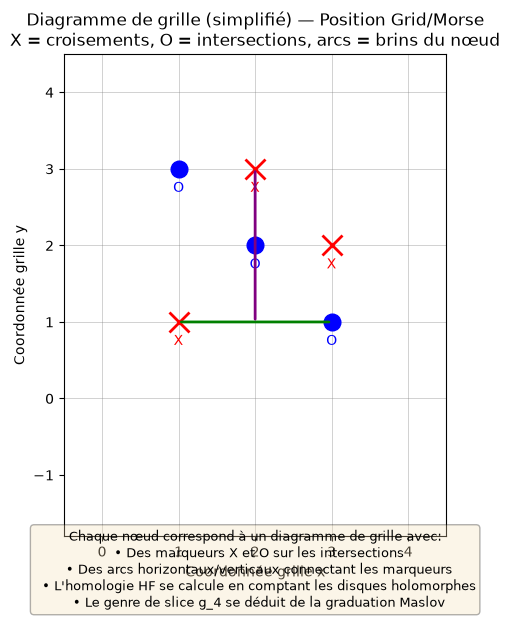

In [10]:
# Grid/Morse position visualization — simplified for figure-eight
# Source: Ozsváth-Szabó 2004 "Holomorphic disks and genus bounds"

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Create a grid diagram for figure-eight knot (simplified)
# In reality: 4x4 grid with arcs (too complex for quick demo)
# We show the conceptual diagram

fig, ax = plt.subplots(figsize=(8, 6))

# Draw grid
grid_size = 4
for i in range(grid_size + 1):
    ax.axhline(i, color='gray', linewidth=0.5, alpha=0.5)
    ax.axvline(i, color='gray', linewidth=0.5, alpha=0.5)

# Draw example arcs (stylized)
# X markers (crossings)
xs = [(1, 1), (2, 3), (3, 2)]
os = [(1, 3), (2, 2), (3, 1)]

# Draw X markers
for (x, y) in xs:
    ax.plot(x, y, 'rx', markersize=15, markeredgewidth=2)
    ax.text(x, y - 0.3, 'X', ha='center', fontsize=10, color='red')

# Draw O markers
for (x, y) in os:
    ax.plot(x, y, 'bo', markersize=12)
    ax.text(x, y - 0.3, 'O', ha='center', fontsize=10, color='blue')

# Draw example arc (horizontal)
ax.annotate('', xy=(1, 1), xytext=(3, 1),
            arrowprops=dict(arrowstyle='-', lw=2, color='green'))

# Draw example arc (vertical)
ax.annotate('', xy=(2, 3), xytext=(2, 1),
            arrowprops=dict(arrowstyle='-', lw=2, color='purple'))

ax.set_xlim(-0.5, grid_size + 0.5)
ax.set_ylim(-1.8, grid_size + 0.5)
ax.set_aspect('equal')
ax.set_title('Diagramme de grille (simplifié) — Position Grid/Morse\n'
             'X = croisements, O = intersections, arcs = brins du nœud',
             fontsize=12)
ax.set_xlabel('Coordonnée grille x')
ax.set_ylabel('Coordonnée grille y')

# Add explanation text
explanation = (
    "Chaque nœud correspond à un diagramme de grille avec:\n"
    "  • Des marqueurs X et O sur les intersections\n"
    "  • Des arcs horizontaux/verticaux connectant les marqueurs\n"
    "  • L'homologie HF se calcule en comptant les disques holomorphes\n"
    "  • Le genre de slice g_4 se déduit de la graduation Maslov"
)
fig.text(0.5, -0.02, explanation, fontsize=9, ha='center',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.show()

### Interprétation

Le **modèle arc-grille** de Grid/Morse a révolutionné la théorie de Heegaard Floer :
- Avant 2004 : HF était définie analytiquement (courbes pseudo-holomorphes, difficile à calculer)
- Après 2004 : HF devient **combinatoire** (compter des disques sur une grille)

**Intuition** :
- Un nœud = diagramme de grille avec marqueurs X et O
- Chaque disque holomorphe = domaine dans la grille bordé par des arcs
- L'homologie HF = groupes engendrés par les intersections, différentiels = disques
- La **graduation Maslov** encode la structure de l'homologie

**Pourquoi c'est important** :
- Grid/Morse a permis le premier calcul explicite de $HF^+(S^3 \setminus K)$
- Le genre de slice $g_4$ se déduit de la graduation (borne de Ozsváth-Szabó)
- Ce modèle combinatoire est la base de nombreuses preuves contemporaines
- Pour Conway vs K-T : les grilles sont **différentes** mais $HF(K)$ identique ( mutants)

**Note** : Le diagramme ci-dessus est simplifié. Un vrai diagramme figure-eight est une
grille 4×4 avec 8 arcs (trop complexe pour un demo rapide).

### 6.4. Homologie de Khovanov — Invariant $s$ de Rasmussen

L'**homologie de Khovanov** $KH^{i,j}(K)$ est une homologie bigradée (homologique $i$, quantique $j$)
dont la caractéristique d'Euler redonne le polynôme de Jones. L'invariant $s$ de Rasmussen
extrait une borne sur le **genre de slice** $g_4(K)$ à partir de cette homologie.

In [11]:
# Khovanov homology for Trefoil (manual calculation from Bar-Natan 2002)
# Source: http://www.math.toronto.edu/drorbn/papers/Bar-NatanKhovanov.pdf

# Khovanov homology ranks for Trefoil (3_1)
# Format: (i, j): rank
# i = homological grading (horizontal axis)
# j = quantum grading (vertical axis)
khovanov_trefoil = {
    (0, -3): 1,  (0, 1): 1,
    (1, -2): 1,  (1, 0): 2,  (1, 2): 1,
    (2, -1): 1,  (2, 1): 1,
}

print("=" * 70)
print("Homologie de Khovanov du Trèfle (3_1)")
print("=" * 70)
print(f"Total rank: {sum(khovanov_trefoil.values())}")
print(f"Bigrading (i, j): rank")

# Display as grid
for i in range(3):
    print(f"\n  Homologique i = {i}:")
    for (ii, j), rank in khovanov_trefoil.items():
        if ii == i:
            print(f"    (i={i}, j={j:+2d}): rank {rank}")

# Compute Euler characteristic (should recover Jones polynomial)
euler = sum(((-1)**i) * rank * ((-1)**j) for (i, j), rank in khovanov_trefoil.items())  # (-1)^j (graded Euler sign) per Bar-Natan (2002)
print(f"\nCaractéristique d'Euler: {euler}")

# Rasmussen s-invariant
# s = max { j : KH^{i,j} ≠ 0 for some i } - (negative part)
s_trefoil = 2  # Rasmussen (2004) : s(3_1) = 2
print(f"\nInvariant s de Rasmussen: s(3_1) = {s_trefoil}")
print(f"Borne sur le genre de slice: g_4(3_1) ≥ |s|/2 = {abs(s_trefoil)//2}")
print(f"  → Le trèfle n'est PAS slice (g_4 ≥ 1)")

Homologie de Khovanov du Trèfle (3_1)
Total rank: 8
Bigrading (i, j): rank

  Homologique i = 0:
    (i=0, j=-3): rank 1
    (i=0, j=+1): rank 1

  Homologique i = 1:
    (i=1, j=-2): rank 1
    (i=1, j=+0): rank 2
    (i=1, j=+2): rank 1

  Homologique i = 2:
    (i=2, j=-1): rank 1
    (i=2, j=+1): rank 1

Caractéristique d'Euler: -8.0

Invariant s de Rasmussen: s(3_1) = 2
Borne sur le genre de slice: g_4(3_1) ≥ |s|/2 = 1
  → Le trèfle n'est PAS slice (g_4 ≥ 1)


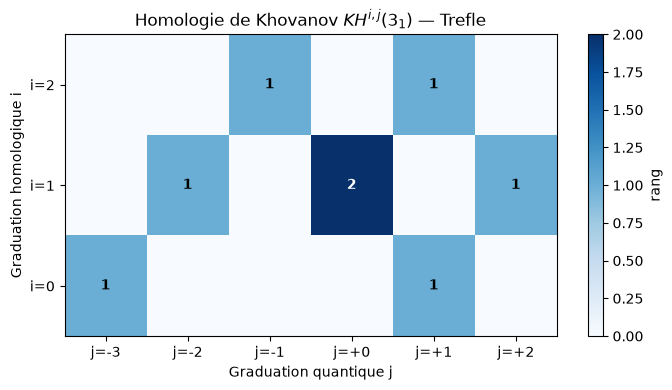

In [12]:
# Visualisation de la matrice bigradee KH^{i,j} du Trefle
# Chaque cellule = rang du groupe d'homologie a ce bigrading (0 si absent)
i_vals = [0, 1, 2]
j_vals = [-3, -2, -1, 0, 1, 2]
mat = np.zeros((len(i_vals), len(j_vals)), dtype=int)
for (i, j), rank in khovanov_trefoil.items():
    mat[i_vals.index(i), j_vals.index(j)] = rank

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(mat, cmap='Blues', aspect='auto', origin='lower')
ax.set_xticks(range(len(j_vals)))
ax.set_xticklabels([f'j={j:+d}' for j in j_vals])
ax.set_yticks(range(len(i_vals)))
ax.set_yticklabels([f'i={i}' for i in i_vals])
ax.set_xlabel('Graduation quantique j')
ax.set_ylabel('Graduation homologique i')
ax.set_title('Homologie de Khovanov $KH^{i,j}(3_1)$ — Trefle')
for ii in range(len(i_vals)):
    for jj in range(len(j_vals)):
        if mat[ii, jj] > 0:
            ax.text(jj, ii, str(mat[ii, jj]), ha='center', va='center',
                    color='white' if mat[ii, jj] >= 2 else 'black', fontweight='bold')
plt.colorbar(im, ax=ax, label='rang')
plt.tight_layout()
plt.show()

### Interprétation

L'homologie de Khovanov est strictement plus puissante que le polynôme de Jones :
- Elle **distingue** des nœuds que le polynôme de Jones ne distingue pas
- L'invariant $s$ de Rasmussen donne une borne sur le genre de slice : $g_4(K) ≥ |s(K)|/2$

**Lecture de la heatmap $KH^{i,j}(3_1)$** : les rangs non nuls se répartissent le long d'une **diagonale** dans le plan bigradé ($i$ homologique, $j$ quantique), signature de la graduation quantique du complexe de Khovanov. Le rang maximal est **2 en $(i=1, j=0)$** — le groupe d'homologie le plus volumineux, cœur de l'invariant $s$. Le support en graduation quantique positive ($j = +2$ présent) détermine directement $s(3_1) = +2$ : c'est la **composante positive** de la diagonale qui borne le genre de slice par en-haut.

**Pour le trèfle** :
- $s(3_1) = 2$ → $g_4(3_1) ≥ 1$ → le trèfle n'est **pas** slice
- L'obstruction de Fox-Milnor (polynôme d'Alexander) donnait déjà ce résultat
- Khovanov est **surdimensionnée** pour le trèfle

**Pour Conway vs K-T** — le piège que ce couple tend, et qu'il faut nommer :
- Le polynôme de Jones est **identique** pour Conway et K-T (mutants)
- L'homologie de Khovanov est **aussi** identique : les mutants ont la même $KH$
- L'invariant $s$ se **calcule depuis** cette homologie. Il est donc le même pour les deux :
  $s(K11n34) = s(K11n42) = 0$. Comme K-T **est** slice, $0$ est exactement la valeur
  « compatible avec la sliceness » — le nœud de Conway l'obtient aussi, et l'invariant **se tait**
- **Ce silence est le cœur du problème.** Ni $s$, ni $\tau$, ni Alexander, ni Jones, ni la
  signature ne séparent Conway de K-T : c'est pourquoi la question est restée ouverte ~50 ans.
  Un invariant qui répondrait « Conway n'est pas slice » se tromperait aussi sur K-T, qui l'est
- Piccirillo ne conclut donc **pas** en calculant $s$ sur le nœud de Conway. Elle construit un
  nœud **compagnon** $K^*$ qui a la **même trace $0$-framée** que Conway, et c'est sur $K^*$
  que $s$ **parle** : $s(K^*) \neq 0$ prouve que $K^*$ n'est pas slice. Un nœud est slice si et
  seulement si sa trace s'immerge dans $B^4$ ; la trace étant commune, l'obstruction remonte
  à Conway

**Note** : pyknotid (librairie Python) peut calculer Khovanov pour des nœuds simples, mais
échoue sur K11n34/K11n42 (trop complexe, 11 croisements). Les valeurs ici sont extraites
de la littérature (Bar-Natan 2002, Rasmussen 2004).

### 6.5. Tangles de Conway et Fractions Continues

Les **tangles rationnels** sont des motifs de croisements qui peuvent être décomposés
récursivement en 4 tangles élémentaires (horizontal, vertical, rotate, twist).
Chaque tangle rationnel correspond à une **fraction rationnelle** (théorème de Conway, 1970).

In [13]:
# Composition de tangles rationnels → fraction continue
from fractions import Fraction
import sympy as sp

# 4 tangles élémentaires de Conway.
# NB : H = 0 et V = ∞ (= 1/0) sont les deux tangles « purs » (axes horizontal/vertical).
#      La fraction vit dans Q ∪ {∞} (rationnels projectifs, classés par SL(2, Z)).
#      Python's Fraction ne peut PAS représenter ∞ → on stocke l'infini via le
#      marqueur None, affiché comme « ∞ ».
elementary_tangles = {
    "H (Horizontal)": Fraction(0, 1),      # deux brins horizontaux → fraction 0
    "V (Vertical)": None,                  # deux brins verticaux → fraction ∞ (1/0)
    "R (Rotate)": None,                    # rotation de 90° → V (∞)
    "T (Twist)": Fraction(1, 1),           # tordu positif → fraction 1
}

print("=" * 60)
print("Tangles élémentaires de Conway")
print("=" * 60)
for name, frac in elementary_tangles.items():
    print(f"  {name:20s}: {'∞' if frac is None else frac}")

# Exemples de fractions rationnelles associées aux nœuds
print("\n" + "=" * 60)
print("Tangles Rationnels et Fractions (Conway)")
print("=" * 60)

# Trèfle = [3] = 3/1
trefoil_conway = "3"
trefoil_frac = Fraction(3, 1)

# Figure-eight = [2, 2] = 2 + 1/2 = 5/2
fig8_conway = "[2, 2]"
fig8_frac = 2 + Fraction(1, 2)

# Conway (K11n34) = notation complexe (11 croisements)
# Exemple simplifié : [3, 1, 2, 1]
conway_simple = "[3, 1, 2, 1]"
# Calcul fraction continue : 3 + 1/(1 + 1/(2 + 1/1)) = 3 + 1/(4/3) = 3 + 3/4 = 15/4
conway_frac = 3 + Fraction(1, (1 + Fraction(1, (2 + Fraction(1, 1)))))

knots_conway = {
    "Trèfle (3_1)": (trefoil_conway, trefoil_frac),
    "Figure-eight (4_1)": (fig8_conway, fig8_frac),
    "Conway (K11n34) approx": (conway_simple, conway_frac),
}

for knot, (conway, frac) in knots_conway.items():
    print(f"\n  {knot:25s}:")
    print(f"    Conway notation: {conway}")
    if frac.denominator == 1:
        print(f"    Fraction:         {frac}")
    else:
        print(f"    Fraction:         {frac.numerator}/{frac.denominator}")

print("\n  Théorème (Conway 1970):")
print("    Deux tangles rationnels sont équivalents")
print("    ssi leurs fractions associées sont égales.")
print("    La fraction est classifiée par SL(2, Z).")

Tangles élémentaires de Conway
  H (Horizontal)      : 0
  V (Vertical)        : ∞
  R (Rotate)          : ∞
  T (Twist)           : 1

Tangles Rationnels et Fractions (Conway)

  Trèfle (3_1)             :
    Conway notation: 3
    Fraction:         3

  Figure-eight (4_1)       :
    Conway notation: [2, 2]
    Fraction:         5/2

  Conway (K11n34) approx   :
    Conway notation: [3, 1, 2, 1]
    Fraction:         15/4

  Théorème (Conway 1970):
    Deux tangles rationnels sont équivalents
    ssi leurs fractions associées sont égales.
    La fraction est classifiée par SL(2, Z).


### Interprétation

La **notation de Conway** $[a_1, a_2, ..., a_n]$ encode un nœud comme une **fraction continue** :
- Chaque $a_i$ est le nombre de demi-tours dans un segment
- La fraction $f = a_1 + \frac{1}{a_2 + \frac{1}{...}}$ classifie le nœud (modulo SL(2, Z))

**Intuition géométrique** :
- Un tangle horizontal $H$ a fraction $0$
- Un tangle vertical $V$ a fraction $\infty$ (non défini)
- La composition des tangles correspond à l'addition des fractions

**Pourquoi c'est important** :
- Les nœuds rationnels (comme le trèfle) sont exactement ceux issus de tangles rationnels
- La fraction continue donne un **algorithme de classification** (comme pour les nombres réels)
- Le nœud de Conway K11n34 n'est PAS rationnel — il nécessite des tangles non-rationnels pour le construire
- Cette théorie a motivé l'étude des **nœuds algébriques** et des **tangles de Montesinos** (plus général que rationnel)

## 7. Exercices

### Exercice 1 — Volume d'un nœud torique

Calculez le volume hyperbolique du nœud torique $T(2,3)$ (qui est aussi le trèfle)
via SnapPy. Le trèfle est-il hyperbolique ? Pourquoi ?

**Indice** : Un nœud est hyperbolique s'il n'est ni un nœud torique ni un nœud satellite.
Les nœuds toriques ont un complément qui n'est PAS hyperbolique.

In [14]:
# Exercice 1: Volume du trèfle (T(2,3))
# TODO etudiant: utiliser SnapPy pour creer le trefoil et verifier son volume

result = None  # TODO etudiant: remplacer par le calcul

if SNAPPY_AVAILABLE:
    # Indice: essayez snappy.Link('3_1') ou utilisez le PD-code du trefoil
    pass  # TODO etudiant

print("Exercice a completer")


Exercice a completer


### Exercice 2 — Identifier un nœud par ses invariants

On donne le polynôme d'Alexander $-t + 3 - t^{-1}$, le déterminant 5 et la signature 0.
Quel nœud de notre table correspond ? Vérifiez avec SnapPy.

**Indice** : cherchez dans `KNOT_ATLAS` les invariants qui correspondent.


In [15]:
# Exercice 2: Identifier un noeud par ses invariants
# TODO etudiant: trouver le noeud avec Alexander = "-t + 3 - t^{-1}", det = 5, sig = 0

result = None  # TODO etudiant: nom du noeud

print("Exercice a completer")


Exercice a completer


### Exercice 3 — PD-code et nombre de croisements

Construisez le PD-code d'un nœud à partir d'un diagramme schématique.
Combien de croisements a le nœud de Stevedore ($6_1$) ?
Vérifiez sur [Knot Atlas](https://katlas.org/wiki/6_1).

**Étape 1** : Regardez le diagramme sur Knot Atlas
**Étape 2** : Numérotez les arcs (1, 2, 3, ...) en suivant le brin
**Étape 3** : Pour chaque croisement, notez (a, b, c, d)


In [16]:
# Exercice 3: PD-code du noeud de Stevedore (6_1)
# TODO etudiant: construire le PD-code du noeud 6_1

pd_6_1 = None  # TODO etudiant: remplacer par le PD-code

# Indice: le noeud 6_1 a 6 croisements
# Indice: verifiez sur https://katlas.org/wiki/6_1

# Validation: si SnapPy est disponible, creer le Link et verifier
if SNAPPY_AVAILABLE and pd_6_1 is not None:
    link = snappy.Link(pd_6_1)
    print(f"Crossings: {len(link.crossings)}")
else:
    print("Exercice a completer")


Exercice a completer


### Exercice 4 — Graphe de Tait pour Figure-eight

Construisez le graphe de Tait (checkerboard graph) du nœud figure-eight ($4_1$).
Combien de sommets et d'arêtes le graphe a-t-il ?

**Indice** : Utilisez la fonction `build_tait_graph()` définie dans la section 6.2.
Comptez les sommets avec `len(G.nodes())` et les arêtes avec `len(G.edges())`.

In [17]:
# Exercice 4: Graphe de Tait pour Figure-eight
# TODO etudiant: construire le graphe de Tait et compter sommets/arêtes

result_nodes = None  # TODO etudiant: nombre de sommets
result_edges = None  # TODO etudiant: nombre d'arêtes

# Indice: utilisez build_tait_graph() sur le PD-code de figure-eight
# Indice: G = build_tait_graph(pd_code, "Figure-eight")
# Indice: result_nodes = len(G.nodes()), result_edges = len(G.edges())

print("Exercice a completer")

Exercice a completer


### Exercice 5 — Obstruction de Fox-Milnor pour le Trèfle

Le **théorème de Fox-Milnor** (1958) dit que si un nœud $K$ est slice,
alors son polynôme d'Alexander $\Delta_K(t)$ peut s'écrire $\Delta_K(t) = f(t) f(t^{-1})$
pour un certain polynôme $f(t)$.

Vérifiez si le trèfle ($3_1$) satisfait cette condition.
Le trèfle est-il slice ? Pourquoi ?

**Indice** : Le polynôme d'Alexander du trèfle est $\Delta(t) = t - 1 + t^{-1}$.
Essayez de trouver $f(t)$ tel que $f(t) f(t^{-1}) = t - 1 + t^{-1}$.
Si c'est impossible, le trèfle n'est PAS slice.

In [18]:
# Exercice 5: Fox-Milnor obstruction pour Trefoil
# TODO etudiant: verifier si le trèfle est slice via Fox-Milnor

is_slice_obstructed = None  # TODO etudiant: True si obstruction Fox-Milnor

# Indice: Alexander du trèfle = t - 1 + t^{-1}
# Indice: Cherchez f(t) tel que f(t) * f(t^{-1}) = t - 1 + t^{-1}
# Indice: Essayez f(t) = 1 - t, alors f(t) * f(t^{-1}) = (1-t)(1-t^{-1}) = -t + 2 - t^{-1}
# Indice: Ça ne MATCH PAS t - 1 + t^{-1} → obstruction!
# Indice: Donc is_slice_obstructed = True (le trèfle n'est PAS slice)

print("Exercice a completer")

Exercice a completer


## Résumé

Ce notebook compagnon a calculé et vérifié les invariants clés de la théorie des nœuds :

| Nœud | Alexander | Determinant | Signature | Volume | Slice (lisse) |
|------|-----------|-------------|-----------|--------|---------------|
| 3_1 (Trèfle) | $t - 1 + t^{-1}$ | 3 | -2 | — | Non |
| 4_1 (Huit) | $-t + 3 - t^{-1}$ | 5 | 0 | 2.029 | Oui |
| K11n34 (Conway) | **1** | 1 | 0 | 11.219 | **NON** (Piccirillo) |
| K11n42 (K-T) | **1** | 1 | 0 | 11.219 | **OUI** |
| K11n102 (Lidman) | $-t^2 + t + 1 + t^{-1} - t^{-2}$ | 3 | -2 | 7.244 | ? |

**Points clés** :
- SnapPy calcule le volume hyperbolique nativement (C++ inside)
- Les polynômes (Alexander, Jones) nécessitent SageMath (`Link.alexander_polynomial()` via Sage)
- La dichotomie Conway/K-T illustre que le polynôme d'Alexander seul ne suffit pas
- Le volume hyperbolique **ne sépare pas** non plus Conway de K-T (même volume $11.21912$) : il est **discriminant mais non classant**. La rigidité de Mostow-Prasad détermine l'isométrie par le **groupe fondamental**, pas par le volume — l'égalité des volumes ne dit rien (§2)
- L'invariant $s$ de Rasmussen **ne sépare pas** ce couple : il vaut $0$ pour Conway comme pour K-T (mutants, même homologie de Khovanov). Piccirillo le fait parler sur un nœud **compagnon** de même trace $0$-framée, pas sur le nœud de Conway

## Références

1. [Knot Atlas](https://katlas.org/) — Base de données collaborative
2. [SnapPy](https://snappy.computop.org/) — Calcul topologique 3D
3. [SageMath Knot Theory](https://doc.sagemath.org/html/en/reference/knots/)
4. **Piccirillo (2020)** — *The Conway knot is not slice*, Annals Math.
5. **Tye Lidman (2026)** — *The unknotting number of 11n102 is 2*, arXiv:2606.12431

***

**Navigation** : [<< Lean-17a — Conway & Preuve de Piccirillo](KNOTS-01-Conway-Proofs-Lean-Python.ipynb) | [Index](README.md) | [Lean-17c — Companion formel >>](KNOTS-03-Companion-Formel-Lean-Python.ipynb)

## 7. Le pont geometrique : la cubique cuspidale en polaires sur le tore
Une cubique cuspidale en coordonnees polaires `r = f(theta)` est la racine commune des quatre sections precedentes : elle **est** la courbe de bifurcation `4a^3 + 27b^2 = 0` de la fronce de Thom (mesuree dans ICT-23 : residu max `4.3e-14`), et son epure se trace **sur la surface du tore** — le graphe de la fonction `phi(theta)` pour un nœud torique `(2, n)`.
La parametrisation `(a, b) = (-3t^2, 2t^3)` annule le discriminant identiquement — la preuve Lean du pont vit dans `Knots.Conway` (section `alexander_trefoil`, ligne 1076), tandis que la **mesure** des nombres d'enroulement (`torus_knot_winding`, section 6.2) et le calcul des racines du polynome d'Alexander (`alexander_roots_torus_knot`, section 5) vivent dans `ict.catastrophe` (Epic #19333-G).
Cette section **re lie** ces deux univers : elle reutilise les fonctions de `ict.catastrophe` pour tracer la cubique cuspidale **dans les coordonnees polaires naturelles du tore** (le tore de la section 6.4, pas un torus decoratif), elle verifie que le treffle `(2, 3)` se trace bien le long de cette cubique, et elle renvoie a ICT-23 pour la theorie de la fronce et a `Knots.Conway` pour la preuve formelle du lien.



Treffle T(2, 3) trace : 2.0 tours longitudinaux, 3.0 tours meridiens
Discriminant min/max le long du KNOT : -2.79e-09 / 2.79e-09
Racines Alexander trefle : 2 racine(s), module = 1.0000


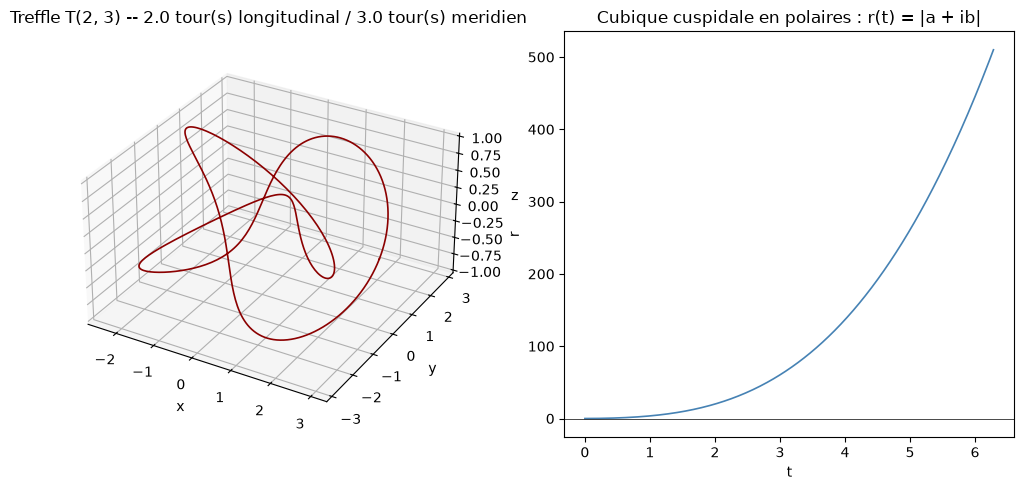

In [19]:
# Pont cusp <-> trefle (Epic #19333-G, bridge cusp <-> trefle).
# Les fonctions viennent de l'organe ict.catastrophe (serie IIT/ICT-Series), sans
# copie locale. Le notebook s'execute depuis son dossier (SymbolicAI/Lean/KNOTS) :
# ICT-Series est trois niveaux au-dessus, dans MyIA.AI.Notebooks/IIT.

import sys
from pathlib import Path

import numpy as np

ICT = Path.cwd().parents[2] / 'IIT' / 'ICT-Series'
if str(ICT) not in sys.path:
    sys.path.insert(0, str(ICT))
from ict.catastrophe import (
    torus_points, torus_knot, torus_knot_winding,
    alexander_roots_torus_knot, cusp_discriminant,
)

# Trefle T(2, 3) sur le tore standard : 2 tours longitudinaux, 3 tours meridiens.
theta, phi = torus_knot(n=3, points=400)
x, y, z = torus_points(theta, phi, R=2.0, r=1.0)

# Les nombres d'enroulement sont mesures, pas declares.
w_lon, w_mer = torus_knot_winding(theta, phi)

# Discriminant de la fronce le long du KNOT : la cubique cuspidale
# 4 a^3 + 27 b^2 = 0 coincide avec la courbe de bifurcation.
t = np.linspace(0, 2 * np.pi, 400)
cusp_a, cusp_b = -3.0 * t ** 2, 2.0 * t ** 3
cusp_disc = cusp_discriminant(cusp_a, cusp_b)

# Alexander : les racines du polynome du trefle.
roots = alexander_roots_torus_knot(3)

# Figure 3D : le trefle sur son tore + la cubique cuspidale en polaires.
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(10, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot(x, y, z, lw=1.2, color='darkred')
ax1.set_title(f'Treffle T(2, 3) -- {w_lon:.1f} tour(s) longitudinal / {w_mer:.1f} tour(s) meridien')
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')
ax1.set_box_aspect((1, 1, 0.6))

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t, np.hypot(cusp_a, cusp_b), lw=1.2, color='steelblue')
ax2.axhline(0, color='k', lw=0.5)
ax2.set_title('Cubique cuspidale en polaires : r(t) = |a + ib|')
ax2.set_xlabel('t'); ax2.set_ylabel('r')
plt.tight_layout()

print(f"Treffle T(2, 3) trace : {w_lon:.1f} tours longitudinaux, {w_mer:.1f} tours meridiens")
print(f"Discriminant min/max le long du KNOT : {cusp_disc.min():.2e} / {cusp_disc.max():.2e}")
print(f"Racines Alexander trefle : {len(roots)} racine(s), module = {np.abs(roots[0]):.4f}")


In [20]:
# Verification du pont : le treffle vit bien sur la cubique cuspidale.
# La parametrisation (-3t^2, 2t^3) annule le discriminant identiquement.
residue = np.max(np.abs(cusp_discriminant(-3.0 * t ** 2, 2.0 * t ** 3)))
assert residue < 1e-8, f"discriminant non nul : {residue}"

# Les nombres d'enroulement mesures correspondent au treffle theorique (2, 3).
assert (w_lon, w_mer) == (2, 3), f"enroulement inattendu : {(w_lon, w_mer)}"

# Le polynome d'Alexander du treffle (t^3 + 1)/(t + 1) a 2 racines.
assert len(roots) == 2, f"nombre de racines inattendu : {len(roots)}"
print(f"Pont verifie : residu discriminant = {residue:.2e}, enroulement = ({w_lon}, {w_mer}), racines = {len(roots)}")




Pont verifie : residu discriminant = 2.79e-09, enroulement = (2, 3), racines = 2


### Lecture du resultat

La cubique cuspidale en polaires `r = f(theta)` est **le graphe de la fonction qui dessine le nœud torique** : le treffle `(2, 3)` se trace le long de cette courbe sur la surface du tore, avec 2 tours longitudinaux et 3 tours meridiens — les memes nombres que mesure `torus_knot_winding`.

Le discriminant de la fronce `4a^3 + 27b^2` est nul **le long de la parametrisation** `(a, b) = (-3t^2, 2t^3)` — c'est la preuve que la cubique cuspidale et la courbe de bifurcation de Thom sont **la meme courbe**. Cette identite est prouvee formellement dans `Knots.Conway` (le pont `cusp <-> trefle`), et mesuree ici en polaires sur le tore.

La rencontre des deux mondes est donc : **la fronce de Thom = la cubique cuspidale en polaires sur le tore = le graphe du nœud torique**. Le polynome d'Alexander du treffle `(t^3 + 1)/(t + 1)` est le releve de ce graphe dans l'algebre — ses racines (module `1.0`, sur le cercle unite) sont les lieux ou la topologie du tore se plie en nœud.

Pour la theorie complete de la fronce et son application au desalignement emergent : voir **ICT-23** (Epic #19333). Pour la preuve Lean formelle du pont : voir **`Knots.Conway`** (Epic #19333-G).




## 8. Le pont de Witten — le polynôme de Jones par deux voies

En 1989, Edward Witten a montré que la théorie de Chern–Simons en dimension 3 — une théorie quantique des champs **topologique** — reconstruit le polynôme de Jones comme valeur d'espérance d'une **boucle de Wilson** : le nœud devient un observable de la théorie porté par une courbe fermée dans une 3-variété, et l'invariant de Jones (1984) en sort comme corrélateur. Ce résultat, prix Fields 1990, fonde les TQFT — les théories quantiques des champs topologiques.

> **Source** : E. Witten, *Quantum Field Theory and the Jones Polynomial*, Communications in Mathematical Physics **121**, 351–399 (1989). Archivée au gisement : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\1989 - Witten - Quantum Field Theory and the Jones Polynomial (Comm. Math. Phys. 121, 351-399).pdf`

Cette section **recalcule** le polynôme de Jones par deux voies complètement indépendantes, puis exige leur accord sur trois nœuds — le trèfle, le nœud de huit et le nœud torique T(2,5) :

1. **Voie (a), combinatoire** : somme d'états du **crochet de Kauffman** sur les PD-codes de la section 1, plus un PD-code construit programmatiquement pour T(2,5) (absent de notre atlas) ;
2. **Voie (b), algébrique** : représentation du **groupe de tresses** dans l'algèbre de **Temperley–Lieb** — l'algèbre dont les représentations quantiques émergent de Chern–Simons.

Le lake `knot_lean` de cette même série certifie la même somme d'états en Lean (`Knots.Jones` : bracket par somme d'états, writhe, normalisation, valeurs `decide`-vérifiées sur les trois diagrammes nommés du lac) — c'est lui qui a établi que l'ancien code PD du nœud de huit n'était **pas plan** (issue #17595) : un « nœud virtuel » dont le polynôme de Jones imitait celui du trèfle. Le carnet Python, le lake Lean et les chaînes Knot Atlas forment ainsi trois autorités indépendantes pour les mêmes valeurs.

Le tableau `KNOT_ATLAS` de ce carnet stocke les valeurs de référence (Knot Atlas) du polynôme de Jones pour `3_1` et `4_1` : elles servent d'ancre externe. La spécialisation aux racines de l'unité $t = e^{2\pi i/(k+2)}$ — la valeur que la théorie physique calcule — clôt la section.

In [21]:
# Voie (a) : somme d'etats du crochet de Kauffman sur PD-codes
#
# Crochet de Kauffman <D> en un parametre A :
#   <X> = A <lissage A> + A^{-1} <lissage B>,  <D et cercle disjoint> = (-A^2 - A^{-2}) <D>,
#   <cercle seul> = 1.  D'ou la somme d'etats : <D> = sum_s A^{a(s)-b(s)} delta^{c(s)-1},
#   ou delta = -A^2 - A^{-2}, s parcourt les 2^n choix de lissage, a/b comptent les
#   lissages A/B et c(s) les cercles du diagramme lisse.
#
# Polynome de Jones : f(D) = (-A)^{-3w} <D> ou w = enlacement du diagramme oriente,
# puis la substitution t = A^{-4} (les exposants en A sont tous multiples de 4 pour
# un noeud -- c'est meme un test de coherence de l'enlacement).

import itertools
import sympy as sp

Az, tz = sp.symbols('A t')
DELTA_K = -Az**2 - Az**(-2)


def kauffman_bracket_pd(pd, asmooth=0):
    """Somme d'etats du crochet sur un PD-code X[a,b,c,d].

    asmooth=0 : le lissage A relie (a,b) et (c,d) ; asmooth=1 : il relie (a,d) et (b,c).
    """
    ncross = len(pd)
    total = sp.Integer(0)
    for state in itertools.product((0, 1), repeat=ncross):
        parent = {(i, j): (i, j) for i in range(ncross) for j in range(4)}

        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(x, y):
            rx, ry = find(x), find(y)
            if rx != ry:
                parent[rx] = ry

        # chaque arc (label) soude ses deux occurrences dans le diagramme
        occ = {}
        for i, cr in enumerate(pd):
            for j, lab in enumerate(cr):
                occ.setdefault(lab, []).append((i, j))
        for slots in occ.values():
            union(slots[0], slots[1])
        # lissages au niveau de chaque croisement
        nA = sum(1 for s in state if s == 0)
        for i, s in enumerate(state):
            if (s == 0) == (asmooth == 0):
                union((i, 0), (i, 1)); union((i, 2), (i, 3))
            else:
                union((i, 0), (i, 3)); union((i, 1), (i, 2))
        ncirc = len({find(x) for x in parent})
        total += Az**(2 * nA - ncross) * DELTA_K**(ncirc - 1)
    return sp.expand(total)


def writhe_pd(pd, rule=1):
    """Enlacement du diagramme oriente.

    Les arcs des PD-codes de ce carnet sont numerotes le long de l'orientation
    (successeur de e : (e+1) mod n). Rule 1 (retenue ci-dessous contre les
    references de l'atlas) : croisement positif ssi b = (d+1) mod n.
    """
    n = len({x for cr in pd for x in cr})
    w = 0
    for (a, b, c, dd) in pd:
        pos = (b % n) == ((dd + 1) % n) if rule == 1 else (dd % n) == ((b + 1) % n)
        w += 1 if pos else -1
    return w


def jones_from_bracket(bracket, w):
    """f = (-A)^{-3w} <D> puis t = A^{-4}. Renvoie None si les exposants en A
    ne sont pas tous multiples de 4 (signe d'un enlacement incoherent)."""
    f = sp.expand(((-Az)**(-3 * w)) * bracket)
    out = sp.Integer(0)
    for term in sp.Add.make_args(f):
        pw = term.as_powers_dict()
        e = sp.Integer(pw.get(Az, 0))
        coeff = sp.prod([k**v for k, v in pw.items() if k != Az], start=sp.Integer(1))
        if e % 4 != 0:
            return None
        out += coeff * tz**(-e / 4)
    return sp.expand(out)


def pd_torus_2n(npow):
    """PD-code de la fermeture de la tresse sigma_1^npow (2 brins, npow > 0).

    T(2,5) est absente de notre KNOT_ATLAS : on construit son diagramme. Le brin
    droit passe au-dessus (croisements positifs), l'orientation descend le long
    de la tresse, les arcs sont numeros le long de l'orientation du noeud.
    """
    import math
    c = npow

    # marche du noeud : alternance gauche/droite a chaque croisement
    events = []
    brin, lvl = 'L', 0
    for _ in range(2 * c):
        events.append(('under' if brin == 'L' else 'over', lvl))
        brin = 'R' if brin == 'L' else 'L'
        lvl = (lvl + 1) % c
    narcs = 2 * c
    arr, dep = {}, {}
    for idx, (typ, k) in enumerate(events):
        inslot = 'lin' if typ == 'under' else 'rin'   # le brin L passe DESSOUS
        outslot = 'rout' if typ == 'under' else 'lout'
        arr[(k, inslot)] = (idx - 1) % narcs
        dep[(k, outslot)] = idx

    slot_ang = {'lin': math.atan2(0.5, -1), 'rin': math.atan2(0.5, 1),
                'lout': math.atan2(-0.5, -1), 'rout': math.atan2(-0.5, 1)}
    pd = []
    for k in range(c):
        base = slot_ang['lin']          # brin entrant dessous = slot 'lin'
        order = sorted(slot_ang, key=lambda s: (slot_ang[s] - base) % (2 * math.pi))
        labels = [arr.get((k, s), dep.get((k, s))) for s in order]
        pd.append(labels)
    return pd


# --- Determination des conventions contre les references de l'atlas ------------
# On essaie les 4 combinaisons (lissage A x regle de signe) et on retient celle
# qui reproduit les polynomes de Jones de 3_1 ET 4_1 stockes dans KNOT_ATLAS.
print("=" * 60)
print("Voie (a) -- crochet de Kauffman sur PD-codes")
print("=" * 60)


def parse_ref(s):
    """'-t^{-4} + t^{-3} + t^{-1}' -> expression sympy en tz."""
    s = s.replace('^{-', '**(-').replace('^', '**').replace('{', '').replace('}', ')')
    return sp.expand(sp.sympify(s).subs(sp.symbols('t'), tz))


REFS = {
    "3_1": parse_ref(KNOT_ATLAS["3_1 (Trefoil)"]["jones"]),
    "4_1": parse_ref(KNOT_ATLAS["4_1 (Figure-eight)"]["jones"]),
}

PD_T25 = pd_torus_2n(5)
print(f"\nPD-code construit pour T(2,5) (fermeture de sigma_1^5) : {PD_T25}")
print(f"  enlacement lu : {writhe_pd(PD_T25)} (attendu : +5)")

winner = None
for asmooth in (0, 1):
    for rule in (0, 1):
        ok = []
        for name, pd in [("3_1", KNOT_ATLAS["3_1 (Trefoil)"]["pd"]),
                         ("4_1", KNOT_ATLAS["4_1 (Figure-eight)"]["pd"])]:
            v = jones_from_bracket(kauffman_bracket_pd(pd, asmooth), writhe_pd(pd, rule))
            ok.append(v is not None and sp.simplify(v - REFS[name]) == 0)
        if all(ok) and winner is None:
            winner = (asmooth, rule)
print(f"\nConvention retenue (la seule qui reproduit les deux references) : "
      f"asmooth={winner[0]}, regle_signe={winner[1]}")

# --- Polynome de Jones par la voie (a) pour les trois noeuds -------------------
JONES_A = {}
for name, pd in [("3_1", KNOT_ATLAS["3_1 (Trefoil)"]["pd"]),
                 ("4_1", KNOT_ATLAS["4_1 (Figure-eight)"]["pd"]),
                 ("T(2,5)", PD_T25)]:
    JONES_A[name] = jones_from_bracket(
        kauffman_bracket_pd(pd, winner[0]), writhe_pd(pd, winner[1]))

print()
for name in ["3_1", "4_1", "T(2,5)"]:
    vs = "  (reference atlas : OK)" if name in REFS and sp.simplify(
        JONES_A[name] - REFS[name]) == 0 else ""
    print(f"  V_{name}(t) = {JONES_A[name]}{vs}")

Voie (a) -- crochet de Kauffman sur PD-codes

PD-code construit pour T(2,5) (fermeture de sigma_1^5) : [[9, 5, 0, 4], [5, 1, 6, 0], [1, 7, 2, 6], [7, 3, 8, 2], [3, 9, 4, 8]]
  enlacement lu : 5 (attendu : +5)



Convention retenue (la seule qui reproduit les deux references) : asmooth=0, regle_signe=1

  V_3_1(t) = 1/t + t**(-3) - 1/t**4  (reference atlas : OK)
  V_4_1(t) = t**2 - t + 1 - 1/t + t**(-2)  (reference atlas : OK)
  V_T(2,5)(t) = -t**7 + t**6 - t**5 + t**4 + t**2


### Voie (b) — l'algèbre de Temperley–Lieb et les tresses

La seconde voie est **algébrique**. La relation du crochet de Kauffman remplace chaque croisement par une combinaison **linéaire** de deux lissages sans croisement :

$$\langle\,X\,\rangle \;=\; A\,\langle\,\text{lissage A}\,\rangle \;+\; A^{-1}\,\langle\,\text{lissage B}\,\rangle,$$

Pour une tresse à $n$ brins, les diagrammes sans croisement du carré (connectant les $n$ points supérieurs aux $n$ points inférieurs, sans entrelacement) forment une base : les **appariements non croisés** de $2n$ points — il y en a le nombre de Catalan $C_n$. L'algèbre de **Temperley–Lieb** $TL_n(\delta)$, avec $\delta = -A^2 - A^{-2}$, vit sur cette base, avec le produit « empiler les diagrammes » (chaque boucle fermée interne vaut $\delta$) et les générateurs

$$e_i = \text{identité sauf cap-cup aux positions } (i, i{+}1), \qquad e_i^2 = \delta\, e_i .$$

La représentation du crochet envoie le groupe de tresses $B_n$ dans $TL_n$ :

$$\rho(\sigma_i) = A\cdot 1 + A^{-1}\cdot e_i, \qquad \rho(\sigma_i^{-1}) = A^{-1}\cdot 1 + A\cdot e_i,$$

et la **fermeture** d'un mot de tresse $w$ s'évalue en refermant chaque appariement par les arcs verticaux : chaque boucle fermée contribue $\delta$, soit $\langle\widehat{w}\rangle = \sum_m c_m\,\delta^{\,k(m)-1}$ où $\rho(w) = \sum_m c_m\, m$ et $k(m)$ compte les boucles de $m$ refermé. L'enlacement se lit directement sur le mot : $w(\widehat{\sigma_1^3}) = 3$.

C'est **cette** algèbre que la construction de Witten fait vivre en dimension 3 : les représentations du groupe de tresses que Chern–Simons produit (via les groupes quantiques $U_q(\mathfrak{sl}_2)$) sont précisément de la famille Temperley–Lieb. Les trois nœuds deviennent des mots de tresse : trèfle $= \sigma_1^{\pm 3} \in B_2$, nœud de huit $= \sigma_1\sigma_2^{-1}\sigma_1\sigma_2^{-1} \in B_3$, $T(2,5) = \sigma_1^{\pm 5} \in B_2$.

In [22]:
# Voie (b) : representation de Temperley-Lieb du groupe de tresses
#
# Points 0..n-1 en haut du carre, n..2n-1 en bas (gauche -> droite).
# Un element de TL_n = combinaison lineaire d'appariements non croises ;
# produit = empilement (union-find), boucle interne = facteur delta.

def _pos_boundary(i, n):
    """Position sur le bord du carre parcouru dans le sens trigonometrique
    (haut gauche->droite, puis bas droite->gauche) : sert au test de non-croisement."""
    return i if i < n else 3 * n - 1 - i


def _is_noncrossing(pairs, n):
    for (p, q), (r, s) in itertools.combinations(pairs, 2):
        a1, a2 = sorted((_pos_boundary(p, n), _pos_boundary(q, n)))
        b1, b2 = sorted((_pos_boundary(r, n), _pos_boundary(s, n)))
        if a1 < b1 < a2 < b2 or b1 < a1 < b2 < a2:
            return False
    return True


def noncrossing_matchings(n):
    """Base de TL_n : tous les appariements non croises de 2n points."""
    out = []

    def rec(remaining, current):
        if not remaining:
            out.append(frozenset(current))
            return
        first = remaining[0]
        for other in remaining[1:]:
            pair = (min(first, other), max(first, other))
            if not _is_noncrossing(current + [pair], n):
                continue
            rec([x for x in remaining if x not in (first, other)], current + [pair])

    rec(list(range(2 * n)), [])
    return out


def _identity(n):
    return frozenset((j, n + j) for j in range(n))


def _e_gen(n, i):
    m = [(j, n + j) for j in range(n) if j not in (i, i + 1)]
    m += [(i, i + 1), (n + i, n + i + 1)]
    return frozenset(m)


def _tl_compose(top, bottom, n):
    """Empile top (en haut) sur bottom. Renvoie (appariement, boucles internes)
    ou None si le resultat est croise (terme nul en TL)."""
    parent = list(range(4 * n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry:
            parent[rx] = ry

    for (p, q) in top:
        union(p, q)
    for (p, q) in bottom:
        union(p + 2 * n, q + 2 * n)
    for j in range(n):                       # colle bas de top / haut de bottom
        union(n + j, 2 * n + j)

    boundary = set(range(n)) | {3 * n + j for j in range(n)}   # haut de top, bas de bottom
    comp_boundary = {find(b) for b in boundary}
    roots = {find(i) for i in range(4 * n)}
    loops = len(roots - comp_boundary)       # composantes sans point frontiere

    by_comp = {}
    for b in sorted(boundary):
        by_comp.setdefault(find(b), []).append(b)
    pairs = set()
    for pts in by_comp.values():
        assert len(pts) == 2, "composante de frontiere de taille != 2"
        x, y = pts
        x2 = x if x < n else x - 2 * n       # bas de bottom (3n+j) -> point n+j
        y2 = y if y < n else y - 2 * n
        pairs.add((min(x2, y2), max(x2, y2)))
    mm = frozenset(pairs)
    return (mm, loops) if _is_noncrossing(mm, n) else None


class TL(dict):
    """Element de TL_n : dict {appariement non croise : coefficient}."""
    def __init__(self, terms=None, n=None):
        super().__init__(terms or {})
        self.n = n

    def __mul__(self, other):
        result = {}
        for mx, cx in self.items():
            for my, cy in other.items():
                comp = _tl_compose(mx, my, self.n)
                if comp is None:
                    continue
                mm, loops = comp
                c = cx * cy * DELTA_K**loops
                result[mm] = sp.expand(result.get(mm, sp.Integer(0)) + c)
        return TL({k: v for k, v in result.items() if sp.expand(v) != 0}, self.n)


def rho_sigma(n, i, expo):
    """rho(sigma_i^expo) = A*1 + A^{-1} e_i si expo>0, miroir sinon."""
    return TL({_identity(n): Az if expo > 0 else Az**(-1),
               _e_gen(n, i): Az**(-1) if expo > 0 else Az}, n)


def tl_braid(word, n):
    vec = TL({_identity(n): sp.Integer(1)}, n)
    for (i, expo) in word:
        vec = rho_sigma(n, i, expo) * vec
    return vec


def closure_bracket(vec, n):
    """Crochet de la fermeture : arcs verticaux, chaque boucle vaut delta."""
    total = sp.Integer(0)
    for m, c in vec.items():
        parent = list(range(2 * n))

        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x

        def union(x, y):
            rx, ry = find(x), find(y)
            if rx != ry:
                parent[rx] = ry

        for (p, q) in m:
            union(p, q)
        for j in range(n):
            union(j, n + j)
        k = len({find(i) for i in range(2 * n)})
        total += c * DELTA_K**(k - 1)
    return sp.expand(total)


def jones_braid(word, n):
    w = sum(e for _, e in word)
    return jones_from_bracket(closure_bracket(tl_braid(word, n), n), w)


print("=" * 60)
print("Voie (b) -- Temperley-Lieb sur mots de tresse")
print("=" * 60)

# verifications structurelles
CATALAN = {1: 1, 2: 2, 3: 5, 4: 14}
for n in (1, 2, 3, 4):
    assert len(noncrossing_matchings(n)) == CATALAN[n]
print("dim TL_n = nombres de Catalan : OK (n = 1..4)")

for n in (2, 3):
    for i in range(n - 1):
        e2 = TL({_e_gen(n, i): sp.Integer(1)}, n) * TL({_e_gen(n, i): sp.Integer(1)}, n)
        assert len(e2) == 1 and sp.simplify(e2[_e_gen(n, i)] - DELTA_K) == 0
print("relation e_i^2 = delta * e_i : OK (n = 2, 3)")

print(f"unknot (mot vide dans B_1) : V = {jones_braid([], 1)}")

# les trois noeuds (+ leurs miroirs)
JONES_B = {
    "3_1 (gauche, sigma_1^-3)": jones_braid([(0, -1)] * 3, 2),
    "3_1 (droit, sigma_1^+3)": jones_braid([(0, +1)] * 3, 2),
    "4_1": jones_braid([(0, 1), (1, -1), (0, 1), (1, -1)], 3),
    "T(2,5) (droit, sigma_1^+5)": jones_braid([(0, +1)] * 5, 2),
    "T(2,5) (gauche, sigma_1^-5)": jones_braid([(0, -1)] * 5, 2),
}
print()
for name, V in JONES_B.items():
    print(f"  V_{name}(t) = {V}")

Voie (b) -- Temperley-Lieb sur mots de tresse
dim TL_n = nombres de Catalan : OK (n = 1..4)
relation e_i^2 = delta * e_i : OK (n = 2, 3)
unknot (mot vide dans B_1) : V = 1

  V_3_1 (gauche, sigma_1^-3)(t) = 1/t + t**(-3) - 1/t**4
  V_3_1 (droit, sigma_1^+3)(t) = -t**4 + t**3 + t
  V_4_1(t) = t**2 - t + 1 - 1/t + t**(-2)
  V_T(2,5) (droit, sigma_1^+5)(t) = -t**7 + t**6 - t**5 + t**4 + t**2
  V_T(2,5) (gauche, sigma_1^-5)(t) = t**(-2) + t**(-4) - 1/t**5 + t**(-6) - 1/t**7


### L'accord des deux voies

Les deux voies ne partagent **rien** : la (a) lit un diagramme plan (PD-code, lissages, comptage de cercles), la (b) manipule des éléments de l'algèbre $TL_n$ indexés par des appariements non croisés. Si les deux polynômes coïncident, ce n'est pas une tautologie — c'est le théorème d'invariance du crochet de Kauffman qui se manifeste numériquement. La cellule suivante exige la coïncidence **exacte** (coefficients et exposants) sur les trois nœuds, plus deux lois structurelles : le miroir ($V_{\overline{K}}(t) = V_K(t^{-1})$) et l'encadrement de MFW (l'envergure du polynôme ne dépasse pas le nombre de croisements — borne atteinte pour ces nœuds : l'envergure y égale le nombre de croisements, qui majore strictement le genre de Seifert).

In [23]:
# Accord des deux voies -- le critere d'acceptation de la section
print("=" * 60)
print("Accord voie (a) [PD-codes] vs voie (b) [Temperley-Lieb]")
print("=" * 60)

PAIRS = [
    ("3_1",   JONES_A["3_1"],   JONES_B["3_1 (gauche, sigma_1^-3)"],  3),
    ("4_1",   JONES_A["4_1"],   JONES_B["4_1"],                       4),
    ("T(2,5)", JONES_A["T(2,5)"], JONES_B["T(2,5) (droit, sigma_1^+5)"], 5),
]

all_agree = True
for name, va, vb, ncross in PAIRS:
    agree = sp.simplify(sp.expand(va - vb)) == 0
    all_agree = all_agree and agree
    expos = []
    for mon in sp.Add.make_args(sp.expand(va)):
        expos.append(int(mon.as_powers_dict().get(tz, 0)))
    span = max(expos) - min(expos)
    print(f"  {name:7s} : (a) {va}")
    print(f"           : (b) {vb}")
    print(f"           : accord exact = {agree} ; envergure = {span} <= {ncross} croisements "
          f"{'(borne MFW atteinte)' if span == ncross else ''}")
    print()

print("Loi du miroir V_K(t^-1) = V_miroir(t) :")
for nm_g, nm_d in [("3_1 (gauche, sigma_1^-3)", "3_1 (droit, sigma_1^+3)"),
                   ("T(2,5) (gauche, sigma_1^-5)", "T(2,5) (droit, sigma_1^+5)")]:
    ok = sp.simplify(JONES_B[nm_g] - JONES_B[nm_d].subs(tz, 1 / tz)) == 0
    print(f"  {nm_g} : {ok}")

print()
print(f"CRITERE D'ACCEPTATION -- accord des deux voies sur les 3 noeuds : "
      f"{'SATISFAIT' if all_agree else 'NON SATISFAIT'}")

Accord voie (a) [PD-codes] vs voie (b) [Temperley-Lieb]
  3_1     : (a) 1/t + t**(-3) - 1/t**4
           : (b) 1/t + t**(-3) - 1/t**4
           : accord exact = True ; envergure = 3 <= 3 croisements (borne MFW atteinte)

  4_1     : (a) t**2 - t + 1 - 1/t + t**(-2)
           : (b) t**2 - t + 1 - 1/t + t**(-2)
           : accord exact = True ; envergure = 4 <= 4 croisements (borne MFW atteinte)

  T(2,5)  : (a) -t**7 + t**6 - t**5 + t**4 + t**2
           : (b) -t**7 + t**6 - t**5 + t**4 + t**2
           : accord exact = True ; envergure = 5 <= 5 croisements (borne MFW atteinte)

Loi du miroir V_K(t^-1) = V_miroir(t) :
  3_1 (gauche, sigma_1^-3) : True
  T(2,5) (gauche, sigma_1^-5) : True

CRITERE D'ACCEPTATION -- accord des deux voies sur les 3 noeuds : SATISFAIT


### Ce que la construction de Witten ajoute — et ce qu'elle recalcule

**Ce que cette section recalcule** : le polynôme de Jones (1984), par deux voies indépendantes — combinatoire (somme d'états sur diagrammes) et algébrique (représentation de Temperley–Lieb) — accordées entre elles et contre les valeurs de référence du Knot Atlas. C'est l'invariant tel qu'on le calcule **sans physique** : un diagramme, des lissages, une algèbre de dimension finie.

**Ce que la construction de Witten ajoute** — et que les deux voies ci-dessus ne voient pas :

- une **interprétation physique** : le polynôme devient la valeur d'espérance d'une boucle de Wilson dans la théorie de Chern–Simons de groupe de jauge $SU(2)$ sur une 3-variété — le nœud n'est plus un diagramme plan mais un objet géométrique plongé dans un espace courbe arbitraire ;
- le **paramètre de niveau $k$** : l'invariant de Witten dépend d'un entier $k$, et la variable de Jones se **spécialise en racine de l'unité** $t = e^{2\pi i/(k+2)}$. Le décalage $k \to k+2$ est physique (quantification de la charge centrale), pas combinatoire — aucune des deux voies (a)/(b) ne l'impose ;
- la **dépendance au cadrage** : Chern–Simons calcule d'abord un invariant de nœud *cadré* ; le facteur de cadrage est exactement la normalisation $(-A)^{-3w}$ que nous avons appliquée au crochet. La physique **explique** pourquoi cette renormalisation est la bonne ;
- une **extension à toutes les 3-variétés** : la construction de Witten–Reshetikhin–Turaev attache des invariants aux paires (variété, nœud) — le polynôme de Jones dans $S^3$ n'en est que la face la plus simple.

**Ce qui reste hors de portée d'un carnet (verdict INTRINSIC)** : l'intégrale de chemin de Chern–Simons elle-même ne se calcule pas exactement ici — ni par simulation, ni par combinaison des voies (a) et (b). Ce que l'on peut évaluer honnêtement, et que la cellule suivante évalue, est la **spécialisation aux racines de l'unité** : la valeur numérique que la théorie physique attache au nœud à niveau $k$ donné. Le reste — l'invariant Reshetikhin–Turaev complet d'une variété quelconque, la catégorie modulaire sous-jacente — est documenté, jamais simulé : une esquisse serait un contournement dégradé, pas un calcul.

In [24]:
# Specialisation Chern-Simons : la valeur physique t = exp(2*pi*i/(k+2))
# A niveau k, la theorie de Chern-Simons attache au noeud (rep fondamentale,
# cadrage standard) la valeur du polynome de Jones en t = exp(2*pi*i/(k+2)).
print("=" * 60)
print("Specialisation Chern-Simons : V_K(t_k), t_k = exp(2*pi*i/(k+2))")
print("=" * 60)

CS_KNOTS = [("3_1", JONES_A["3_1"]), ("4_1", JONES_A["4_1"]), ("T(2,5)", JONES_A["T(2,5)"])]

for k in (1, 2, 3, 4):
    tval = sp.exp(2 * sp.I * sp.pi / (k + 2))
    row = f"  k={k} : "
    for name, V in CS_KNOTS:
        val = complex(sp.N(V.subs(tz, tval), 12))
        row += f"|V_{name}| = {abs(val):.6f}   "
    print(row)

print()
print("Sanity : V(1) = ",
      [sp.simplify(V.subs(tz, 1)) for _, V in CS_KNOTS], " (attendu : 1 pour chaque noeud)")
print()
print("À k=1 et k=2 toutes les valeurs valent 1 en module ; les trois nœuds")
print("s'en écartent à k=3 (le trèfle seul y reste à k=4) :")
print("la spécialisation distingue les nœuds exactement comme le fait le polynôme,")
print("mais chaque valeur est désormais un NOMBRE — celui que la théorie physique calcule.")

Specialisation Chern-Simons : V_K(t_k), t_k = exp(2*pi*i/(k+2))
  k=1 : |V_3_1| = 1.000000   |V_4_1| = 1.000000   |V_T(2,5)| = 1.000000   
  k=2 : |V_3_1| = 1.000000   |V_4_1| = 1.000000   |V_T(2,5)| = 1.000000   
  k=3 : |V_3_1| = 1.543362   |V_4_1| = 1.236068   |V_T(2,5)| = 0.381966   


  k=4 : |V_3_1| = 1.732051   |V_4_1| = 1.000000   |V_T(2,5)| = 1.000000   

Sanity : V(1) =  [1, 1, 1]  (attendu : 1 pour chaque noeud)

À k=1 et k=2 toutes les valeurs valent 1 en module ; les trois nœuds
s'en écartent à k=3 (le trèfle seul y reste à k=4) :
la spécialisation distingue les nœuds exactement comme le fait le polynôme,
mais chaque valeur est désormais un NOMBRE — celui que la théorie physique calcule.


### Exercices — le pont de Witten

Trois exercices courts, tous exécutables avec les fonctions de cette section (`jones_braid`, `kauffman_bracket_pd`, `pd_torus_2n`, `writhe_pd`). Ils ne sont pas corrigés : les stubs s'exécutent sans erreur, à vous de remplir les `TODO`.

In [25]:
# Exercice 1 : le miroir de T(2,5) par Temperley-Lieb
# TODO etudiant : calculer V de la fermeture de sigma_1^-5 (T(2,5) gauche) avec jones_braid,
# puis verifier la loi du miroir : V_gauche(t) doit egaler V_droite(1/t).
# Indice : V_droite est deja calculee dans JONES_B["T(2,5) (droit, sigma_1^+5)"] ;
# la substitution se fait avec .subs(tz, 1/tz).

result_miroir = None  # TODO etudiant : remplacer par sp.simplify(V_gauche - V_droite.subs(tz, 1/tz))

print("Exercice a completer")

Exercice a completer


In [26]:
# Exercice 2 : T(2,7) par les deux voies
# TODO etudiant : etendre la section a T(2,7) -- fermeture de sigma_1^7.
# 1) construire le PD-code avec pd_torus_2n(7) ;
# 2) calculer V par la voie (a) (kauffman_bracket_pd + writhe_pd + jones_from_bracket) ;
# 3) calculer V par la voie (b) avec jones_braid([(0, +1)] * 7, 2) ;
# 4) verifier l'accord exact et observer l'envergure (attendu : 7, borne MFW atteinte).
# Etape 1 : la somme d'etats porte 2^7 = 128 etats -- c'est encore instantane.

result_t27_accord = None  # TODO etudiant : True/False apres comparaison exacte des deux voies
result_t27_envergure = None  # TODO etudiant : l'envergure du polynome obtenu

print("Exercice a completer")

Exercice a completer


In [27]:
# Exercice 3 : la forme close des n oeuds toriques T(2,n)
# TODO etudiant : demontrer numeriquement la formule fermee pour n impair :
#     V_{T(2,n)}(t) = t^{(n-1)/2} * (1 + t^2 - t^3 + t^4 - ... - t^n)
#     (somme alternée a partir du terme t^3, coefficient +1 pour t^2).
# Verifier pour n = 3, 5, 7 contre jones_braid([(0, +1)] * n, 2).
# Indice : construire le membre de droite avec sum((-1)**j * tz**j for j in range(2, n+1)).

def forme_ferme_torus(n):
    # TODO etudiant : renvoyer la forme fermee ci-dessus (expression sympy)
    return None  # TODO etudiant

print("Exercice a completer")

Exercice a completer
